# **Project Name**    - Classification - Flipkart Customer Service Satisfaction




##### **Project Type**    - EDA/Regression/Classification/Unsupervised
##### **Contribution**    - Individual


# **Project Summary -**

The Flipkart Customer Service Satisfaction Classification project aims to analyze customer support interactions and predict Customer Satisfaction (CSAT) scores using machine learning techniques. Customer satisfaction is an important indicator of service quality, customer loyalty, and overall business performance. By analyzing customer service data, this project seeks to understand the factors that influence customer experiences and identify opportunities to improve the effectiveness of customer support operations.

The project begins with data understanding and preprocessing, including examining dataset structure, handling missing values, checking duplicate records, identifying inconsistencies, and preparing relevant features for analysis. Exploratory Data Analysis (EDA) will be performed using statistical summaries and visualizations to understand customer satisfaction patterns, the distribution of CSAT scores, and relationships between variables such as customer support channels, issue categories, agent performance, response times, and resolution-related information, depending on data availability. Correlation analysis and feature analysis will help identify meaningful relationships within the dataset.

Following data preprocessing and exploration, suitable machine learning classification algorithms will be developed to predict customer satisfaction scores. The dataset will be divided into training and testing sets to assess how well the models perform on unseen data. Appropriate preprocessing techniques, including categorical encoding and numerical feature scaling where necessary, will be incorporated into the modelling pipeline. Multiple classification algorithms, such as Logistic Regression, Decision Tree, Random Forest, and other suitable models, will be compared to identify the most effective approach for the available data.

Model evaluation will be conducted using relevant performance metrics, including accuracy, precision, recall, F1-score, and confusion matrices. Since customer satisfaction scores may be distributed unevenly across classes, particular attention will be given to class imbalance and the limitations of accuracy as a standalone metric. Cross-validation and hyperparameter tuning will be used where appropriate to improve model performance and reduce overfitting. Feature importance and model interpretation techniques will also be considered to understand which customer service characteristics contribute most to the predictions.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


Flipkart handles a large volume of customer service interactions, making it challenging to consistently assess and improve customer satisfaction. The project aims to analyze customer support data, identify key factors influencing Customer Satisfaction (CSAT) scores, and develop machine learning classification models to predict customer satisfaction. The insights generated will help identify service improvement opportunities and support data-driven decisions to enhance customer experience.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:

# Data manipulation and numerical computation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis and hypothesis testing
from scipy import stats

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Classification algorithms
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Handling class imbalance
from sklearn.utils.class_weight import compute_class_weight

# Model saving
import joblib

import warnings
import os
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)


### Dataset Loading

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Customer_support_data.csv to Customer_support_data.csv


### Dataset First View

In [3]:
import pandas as pd

df = pd.read_csv('Customer_support_data.csv')
df.head()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns Count

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 85907
Number of columns: 20


### Dataset Information

In [4]:
# Dataset Info

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name            

#### Duplicate Values

In [4]:
# Dataset Duplicate Value Count

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


#### Missing Values/Null Values

In [6]:
# Missing Values/Null Values Count

print(df.isnull().sum())

Unique id                      0
channel_name                   0
category                       0
Sub-category                   0
Customer Remarks           57165
Order_id                   18232
order_date_time            68693
Issue_reported at              0
issue_responded                0
Survey_response_Date           0
Customer_City              68828
Product_category           68711
Item_price                 68701
connected_handling_time    85665
Agent_name                     0
Supervisor                     0
Manager                        0
Tenure Bucket                  0
Agent Shift                    0
CSAT Score                     0
dtype: int64


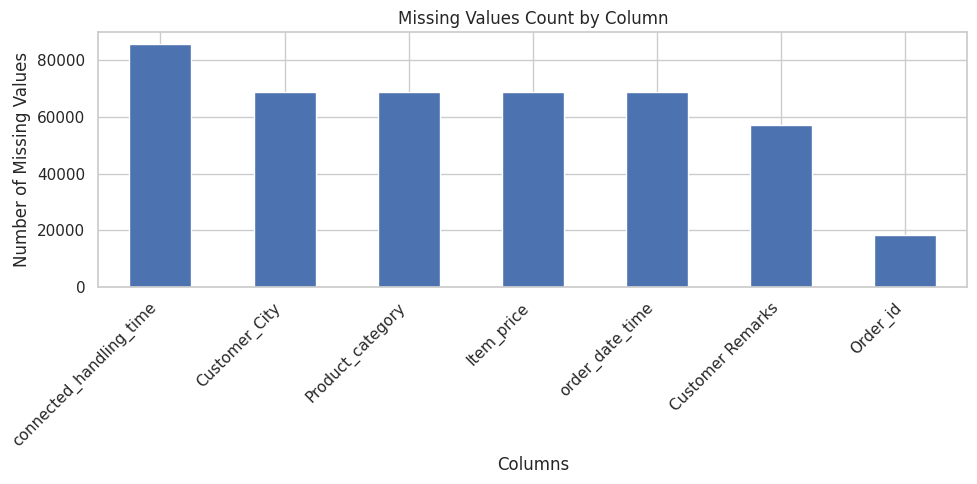

In [7]:
# Missing Values Count by Column

missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(10, 5))
missing_values.sort_values(ascending=False).plot(kind='bar')

plt.title("Missing Values Count by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### What did you know about your dataset?

The dataset contains information related to Flipkart's customer service interactions. It can be used to understand customer experiences and identify the factors that influence customer satisfaction.

The dataset includes customer service-related information such as interaction channels, issue categories, agent details, product-related information, handling time, and customer satisfaction scores, depending on the available columns.

The main objective of this project is to analyze customer service patterns and build a machine learning classification model to predict customer satisfaction. The analysis can help identify areas where customer service needs improvement, support better agent performance, and improve the overall customer experience.

Before building the model, I will examine the dataset's structure, data types, missing values, duplicate records, and target variable distribution to understand its quality and suitability for analysis.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns

print("Columns in the dataset:")
for column in df.columns:
    print(column)

Columns in the dataset:
Unique id
channel_name
category
Sub-category
Customer Remarks
Order_id
order_date_time
Issue_reported at
issue_responded
Survey_response_Date
Customer_City
Product_category
Item_price
connected_handling_time
Agent_name
Supervisor
Manager
Tenure Bucket
Agent Shift
CSAT Score


In [8]:
# Dataset Describe

df.describe()

,Item_price,connected_handling_time,CSAT Score
count,17206.000000,242.000000,85907.000000
mean,5660.774846,462.400826,4.242157
std,12825.728411,246.295037,1.378903
min,0.000000,0.000000,1.000000
25%,392.000000,293.000000,4.000000
50%,979.000000,427.000000,5.000000
75%,2699.750000,592.250000,5.000000
max,164999.000000,1986.000000,5.000000


### Variables Description

The Flipkart Customer Service Satisfaction dataset contains variables related to customer service interactions, customer issues, agent performance, and customer satisfaction.
- Customer Service Channel: Indicates the channel through which the customer contacted customer support.
- Issue Category and Sub-category: Describe the type of problem or query raised by the customer.
- Product Category: Identifies the category of the product associated with the interaction.
- Agent Shift: Represents the shift during which the customer service agent handled the interaction.
- Tenure Bucket: Indicates the agent's experience or tenure group.
- Item Price: Represents the price of the product associated with the interaction.
- Connected Handling Time: Represents the time spent handling the customer interaction.
- Customer Remarks: Contains customer-provided comments or feedback, where available.
- CSAT Score: Represents the customer satisfaction score and serves as the target variable for the classification task.

### Check Unique Values for each variable.

In [10]:
# Check Unique Values for Each Variable

for column in df.columns:
    print(f"\nUnique values in {column}:")
    print(df[column].unique())


Unique values in Unique id:
['7e9ae164-6a8b-4521-a2d4-58f7c9fff13f'
 'b07ec1b0-f376-43b6-86df-ec03da3b2e16'
 '200814dd-27c7-4149-ba2b-bd3af3092880' ...
 '723bce2c-496c-4aa8-a64b-ca17004528f0'
 '707528ee-6873-4192-bfa9-a491f1c08ab5'
 '07c7a878-0d5a-42e0-97ef-de59abec0238']

Unique values in channel_name:
['Outcall' 'Inbound' 'Email']

Unique values in category:
['Product Queries' 'Order Related' 'Returns' 'Cancellation'
 'Shopzilla Related' 'Payments related' 'Refund Related' 'Feedback'
 'Offers & Cashback' 'Onboarding related' 'Others' 'App/website']

Unique values in Sub-category:
['Life Insurance' 'Product Specific Information' 'Installation/demo'
 'Reverse Pickup Enquiry' 'Not Needed' 'Fraudulent User'
 'Exchange / Replacement' 'Missing' 'General Enquiry' 'Return request'
 'Delayed' 'Service Centres Related' 'Payment related Queries'
 'Order status enquiry' 'Return cancellation' 'Unable to track'
 'Seller Cancelled Order' 'Wrong' 'Invoice request' 'Priority delivery'
 'Refund Relat

## 3. ***Data Wrangling***

### Data Wrangling Code

In [4]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove leading and trailing spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Remove leading and trailing spaces from text values
for column in df_clean.select_dtypes(include='object').columns:
    df_clean[column] = df_clean[column].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Check missing values
print("Missing values in each column:")
print(df_clean.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# Display dataset shape after cleaning
print("Rows and columns after cleaning:", df_clean.shape)

# Display the cleaned dataset
df_clean.head()

Missing values in each column:
Unique id                      0
channel_name                   0
category                       0
Sub-category                   0
Customer Remarks           57165
Order_id                   18232
order_date_time            68693
Issue_reported at              0
issue_responded                0
Survey_response_Date           0
Customer_City              68828
Product_category           68711
Item_price                 68701
connected_handling_time    85665
Agent_name                     0
Supervisor                     0
Manager                        0
Tenure Bucket                  0
Agent Shift                    0
CSAT Score                     0
dtype: int64
Duplicate rows: 0
Rows and columns after cleaning: (85907, 20)


,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### What all manipulations have you done and insights you found?

Data manipulations performed:
1. Created a copy of the dataset: Created df_clean to preserve the original dataset.
2. Removed duplicate records: Removed exact duplicate rows to reduce repeated observations.
3. Cleaned column names: Removed leading and trailing spaces from column names for consistency.
4. Cleaned text values: Removed unnecessary leading and trailing spaces from text columns.
5. Checked missing values: Identified null values in each column to determine where further treatment may be required.
6. Validated the cleaned dataset: Checked the remaining duplicate count and the final number of rows and columns.
Insights found:
- Duplicate records can affect the reliability of statistical analysis and model training.
- Inconsistent spaces in text values can create unnecessary categories and affect categorical analysis.
- Missing values need to be assessed before deciding whether to fill or remove them.
- Understanding the dataset's structure and data quality is an important step before exploratory data analysis and classification modeling.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

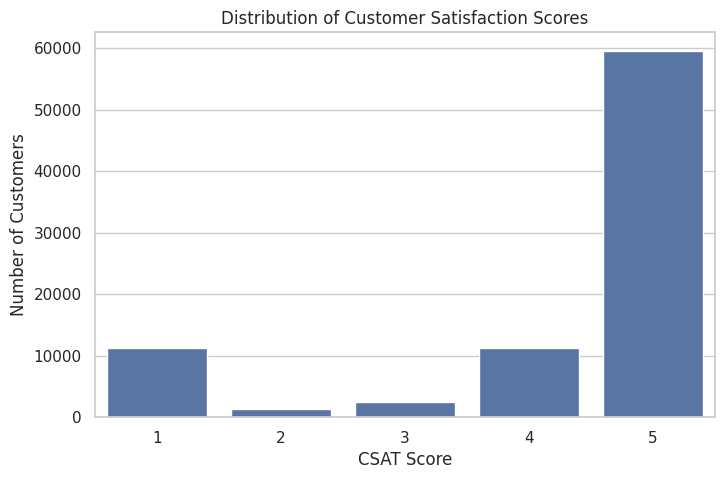

In [14]:
# Chart - 1: Customer Satisfaction Score Distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='CSAT Score')

plt.title('Distribution of Customer Satisfaction Scores')
plt.xlabel('CSAT Score')
plt.ylabel('Number of Customers')
plt.show()

##### 1. Why did you pick the specific chart?

I selected a count plot because the CSAT Score variable represents discrete satisfaction ratings. A count plot clearly shows the number of customer interactions belonging to each score category, making it easy to compare customer satisfaction levels and identify the most and least frequent ratings. It also helps assess whether the target variable is imbalanced, which is important when building a classification model.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify the distribution of customer satisfaction scores across different rating categories. It can reveal which CSAT score is most common and whether low satisfaction ratings occur less frequently than high ratings. This also helps determine whether the target variable is imbalanced, which may affect classification model performance.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Understanding the distribution of customer satisfaction scores can help Flipkart evaluate its customer service performance and identify areas for improvement. If the chart shows a high number of low satisfaction scores, the company can investigate customer complaints, improve agent training, and address recurring service issues. If high scores dominate, Flipkart can identify and maintain the practices that contribute to positive customer experiences.

An uneven distribution of CSAT scores may indicate a potential business concern if low satisfaction ratings represent a meaningful number of customer interactions. Customer dissatisfaction can contribute to reduced customer loyalty, negative reviews, and potential loss of repeat purchases.
Additionally, if one satisfaction category dominates the dataset, the classification model may become biased toward predicting that category and perform poorly on less frequent ratings. This could cause Flipkart to overlook dissatisfied customers who need attention.

#### Chart - 2

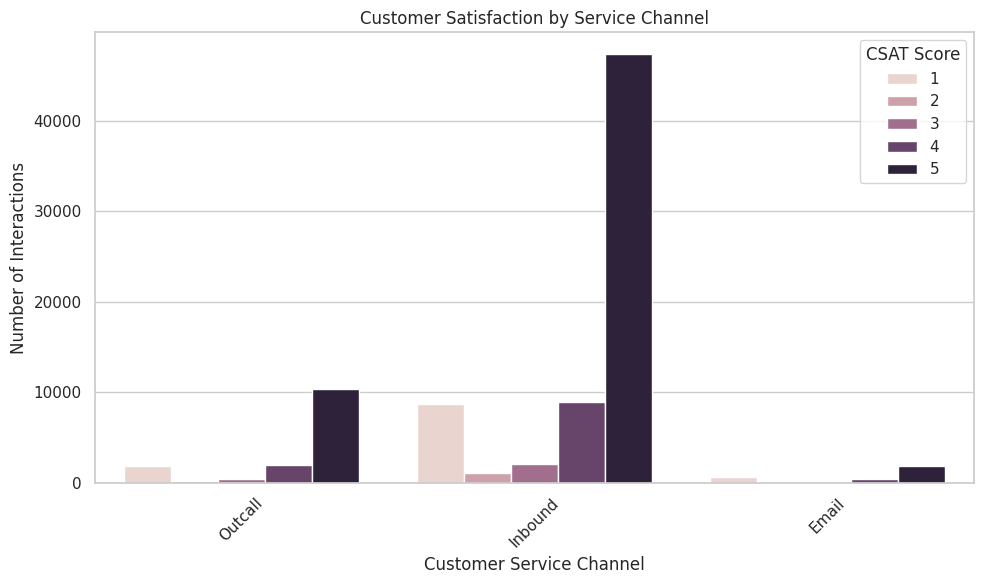

In [15]:
# Chart - 2: CSAT Score by Customer Service Channel

plt.figure(figsize=(10, 6))

sns.countplot(data=df_clean, x='channel_name', hue='CSAT Score')

plt.title('Customer Satisfaction by Service Channel')
plt.xlabel('Customer Service Channel')
plt.ylabel('Number of Interactions')
plt.xticks(rotation=45)
plt.legend(title='CSAT Score')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares the distribution of satisfaction scores across service channels, helping reveal differences in customer feedback

##### 2. What is/are the insight(s) found from the chart?

The chart helps compare customer satisfaction scores across different customer service channels. It shows how customer feedback varies between channels and helps identify which channels may have a higher concentration of low or high satisfaction ratings.
Flipkart can use these findings to improve channel-specific support processes and allocate training or resources where they are most needed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Analyzing customer satisfaction across service channels can help Flipkart identify which channels may need improvement. If certain channels receive relatively more low satisfaction ratings, the company can investigate response times, communication quality, and issue resolution processes. Improving these areas can increase customer satisfaction, strengthen customer loyalty, and encourage repeat purchases.

Are there any insights that lead to negative growth? Justify with specific reasons.
- Poor channel performance: A high proportion of low CSAT scores in a particular channel may indicate unresolved customer issues or an unsatisfactory support experience, potentially reducing customer retention.
- Uneven service quality: Significant differences in satisfaction across channels may suggest inconsistent service standards, which can weaken customer trust.
- Resource allocation issues: If underperforming channels are not identified and addressed, continued service problems may lead to complaints, negative reviews, and additional support costs.

#### Chart - 3

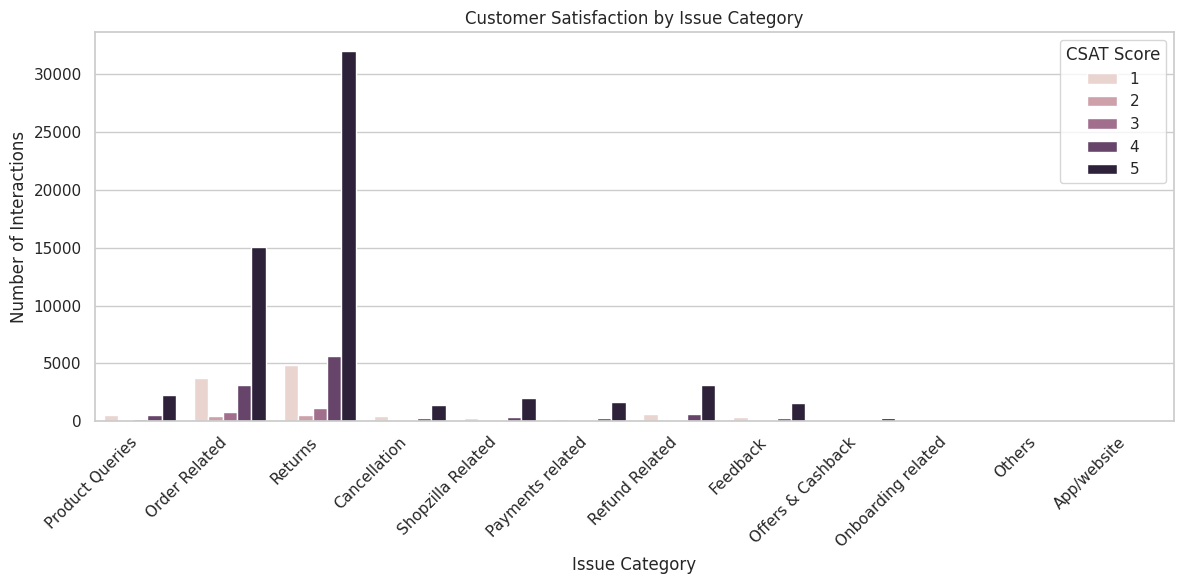

In [16]:
# Chart - 3: CSAT Score by Issue Category

plt.figure(figsize=(12, 6))

sns.countplot(data=df_clean, x='category', hue='CSAT Score')

plt.title('Customer Satisfaction by Issue Category')
plt.xlabel('Issue Category')
plt.ylabel('Number of Interactions')
plt.xticks(rotation=45, ha='right')
plt.legend(title='CSAT Score')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

t compares the distribution of satisfaction ratings across issue categories, helping identify which types of customer problems may require closer attention.

##### 2. What is/are the insight(s) found from the chart?

The chart helps compare customer satisfaction across different issue categories handled by Flipkart's customer service team. It can reveal which categories have relatively more low satisfaction ratings and which receive more positive feedback.
- Customer pain points: Categories with a higher proportion of low CSAT scores may indicate recurring problems or difficulties in resolving customer issues.
- Service improvement opportunities: Categories with weaker satisfaction results may require better resolution procedures, clearer communication, or additional agent training.
- Best practices: Categories with stronger satisfaction results can be studied to identify effective customer service practices.
- Business implications: Addressing dissatisfaction in problematic categories may improve customer loyalty, reduce repeat complaints, and enhance the overall support experience

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Analyzing customer satisfaction across issue categories can help Flipkart identify the types of customer problems that need more attention. By improving resolution procedures, providing targeted agent training, and addressing recurring complaints, Flipkart can improve customer satisfaction, strengthen customer loyalty, and encourage repeat purchases.

Are there any insights that lead to negative growth? Justify with specific reasons.
- Recurring customer issues: If certain categories have a high proportion of low CSAT scores, unresolved problems may lead to customer dissatisfaction and reduced retention.
- Inefficient issue resolution: Categories with consistently poor satisfaction may indicate delays, repeated customer contacts, or ineffective resolution processes, potentially increasing support costs.
- Reputational risk: Continued dissatisfaction in important product or service categories may result in negative reviews and reduced customer trust.

#### Chart - 4

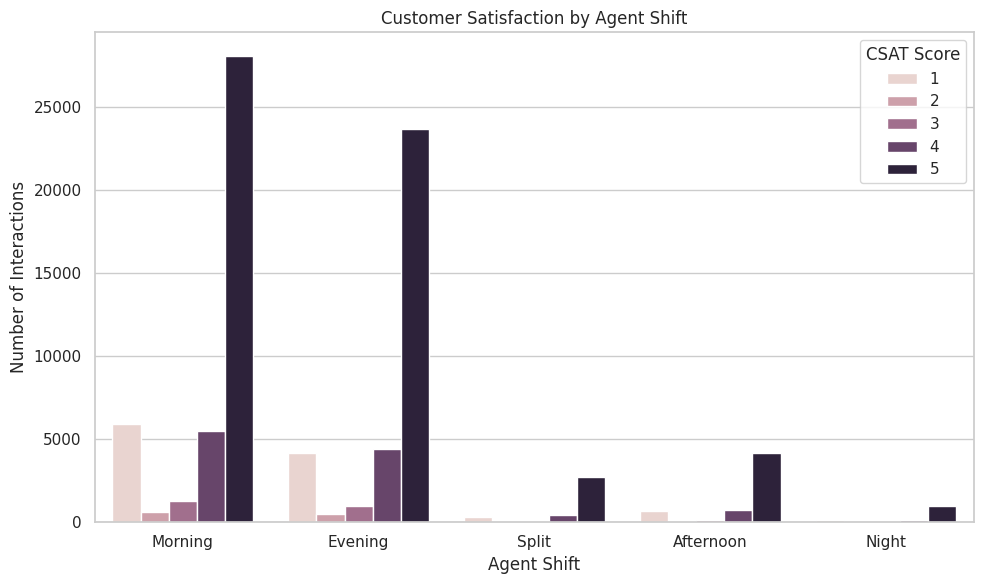

In [17]:
# Chart - 4: Customer Satisfaction by Agent Shift

plt.figure(figsize=(10, 6))

sns.countplot(data=df_clean, x='Agent Shift', hue='CSAT Score')

plt.title('Customer Satisfaction by Agent Shift')
plt.xlabel('Agent Shift')
plt.ylabel('Number of Interactions')
plt.legend(title='CSAT Score')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a count plot because Agent Shift is a categorical variable and CSAT Score represents discrete satisfaction ratings. The chart makes it easy to compare the distribution of customer satisfaction scores across different agent shifts. It helps identify potential differences in customer experience and determine whether particular shifts may require improvements in staffing, workload management, or agent training

##### 2. What is/are the insight(s) found from the chart?

The chart helps us understand how customer satisfaction differs across agent shifts. It can show if any shift has more low satisfaction scores than others. This can help Flipkart identify where better staffing, workload management, or agent training may be needed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help Flipkart improve customer satisfaction by identifying shifts that may need better staffing or agent training.
If a particular shift has more low satisfaction scores, it could indicate workload issues or delays in resolving customer problems. If these issues continue, they may lead to customer dissatisfaction, negative reviews, and loss of customers. Improving service quality across all shifts can help build customer trust and loyalty.

#### Chart - 5

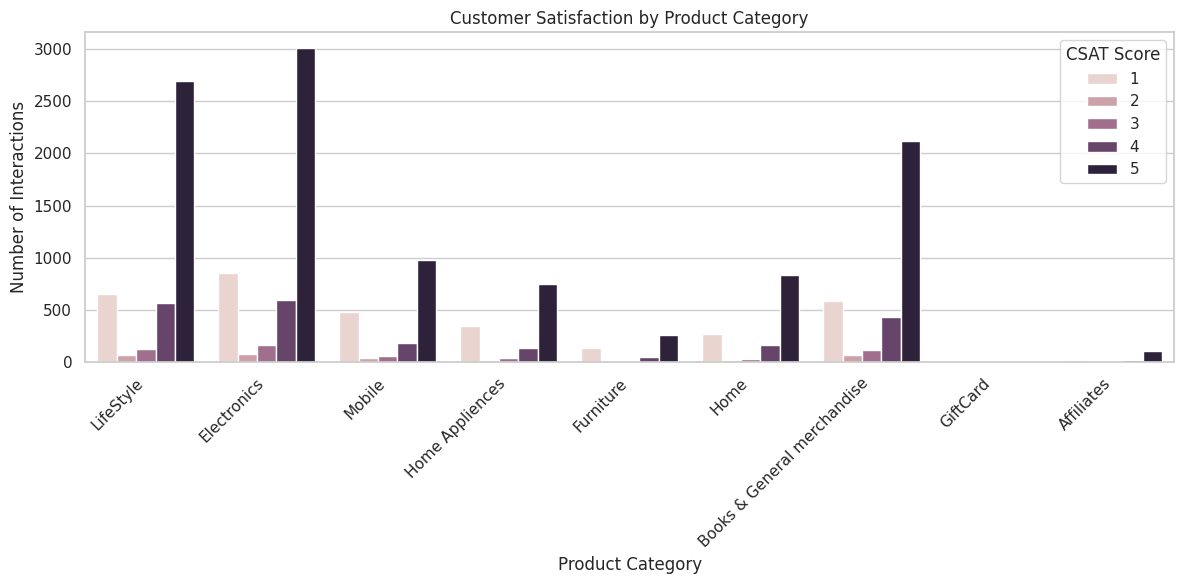

In [18]:
# Chart - 5: CSAT Score by Product Category

plt.figure(figsize=(12, 6))

sns.countplot(data=df_clean, x='Product_category', hue='CSAT Score')

plt.title('Customer Satisfaction by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Interactions')
plt.xticks(rotation=45, ha='right')
plt.legend(title='CSAT Score')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a count plot because it makes it easy to compare customer satisfaction scores across different product categories. It helps us understand which categories have more low or high ratings and where Flipkart may need to improve customer support.

##### 2. What is/are the insight(s) found from the chart?

The chart helps us understand how customer satisfaction varies across different product categories. It shows which categories have more low or high satisfaction scores. This can help Flipkart identify product categories where customer support may need improvement.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help Flipkart improve customer satisfaction and business growth. Product categories with more low satisfaction scores may need better support, faster issue resolution, or improved handling of customer complaints.
If these issues continue, they could lead to negative reviews, reduced customer loyalty, and fewer repeat purchases. Identifying problem areas early can help Flipkart improve its service and build better customer relationships.

#### Chart - 6

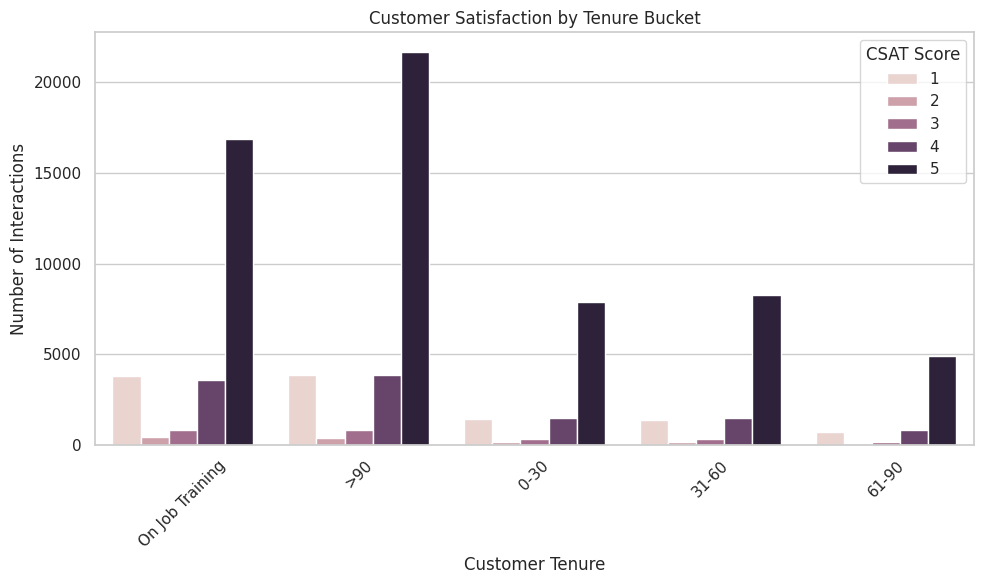

In [19]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df_clean, x='Tenure Bucket', hue='CSAT Score')

plt.title('Customer Satisfaction by Tenure Bucket')
plt.xlabel('Customer Tenure')
plt.ylabel('Number of Interactions')
plt.legend(title='CSAT Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a count plot because it makes it easy to compare customer satisfaction scores across different customer tenure groups. It helps us understand whether newer or longer-term customers report different levels of satisfaction.

##### 2. What is/are the insight(s) found from the chart?

The chart helps us understand how customer satisfaction differs between new and long-term customers. It can show whether certain tenure groups have more low satisfaction scores than others. This can help Flipkart identify customer groups that may need better support and improve their overall experience.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help Flipkart improve customer satisfaction and retain customers. If newer or long-term customers have more low satisfaction scores, Flipkart can identify their problems and provide better support.
If customer issues remain unresolved, it may lead to negative reviews, reduced customer loyalty, and fewer repeat purchases. Addressing these issues can help Flipkart improve customer retention and support long-term business growth.

#### Chart - 7

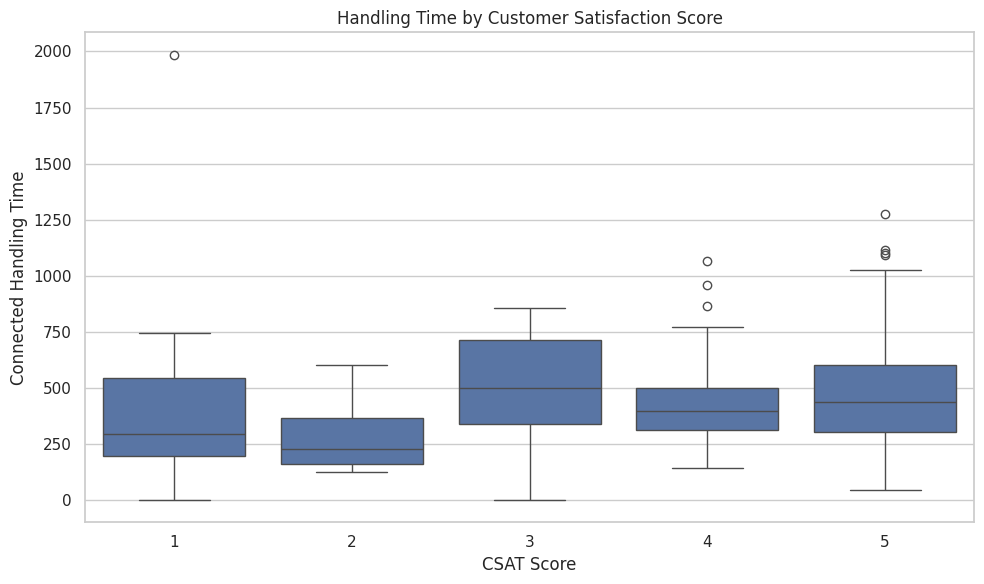

In [20]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_clean, x='CSAT Score', y='connected_handling_time')

plt.title('Handling Time by Customer Satisfaction Score')
plt.xlabel('CSAT Score')
plt.ylabel('Connected Handling Time')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a box plot because it helps compare the distribution of handling times across different CSAT scores. It shows the typical handling time, variation, and any unusual values, helping us understand whether handling time may be related to customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

The chart helps us understand how handling time varies across different customer satisfaction scores. If lower CSAT scores have longer handling times, it may indicate delays or difficulties in resolving customer issues. These insights can help Flipkart review its support process and improve resolution efficiency. The actual trend should be confirmed from the plotted results.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help Flipkart improve customer satisfaction by identifying whether longer handling times are linked to lower ratings. The company can review its support process and train agents to resolve issues more efficiently.
If customers spend too much time waiting for a resolution, they may become dissatisfied, leave negative reviews, or avoid shopping with Flipkart again. This can reduce customer loyalty and negatively affect business growth.

#### Chart - 8

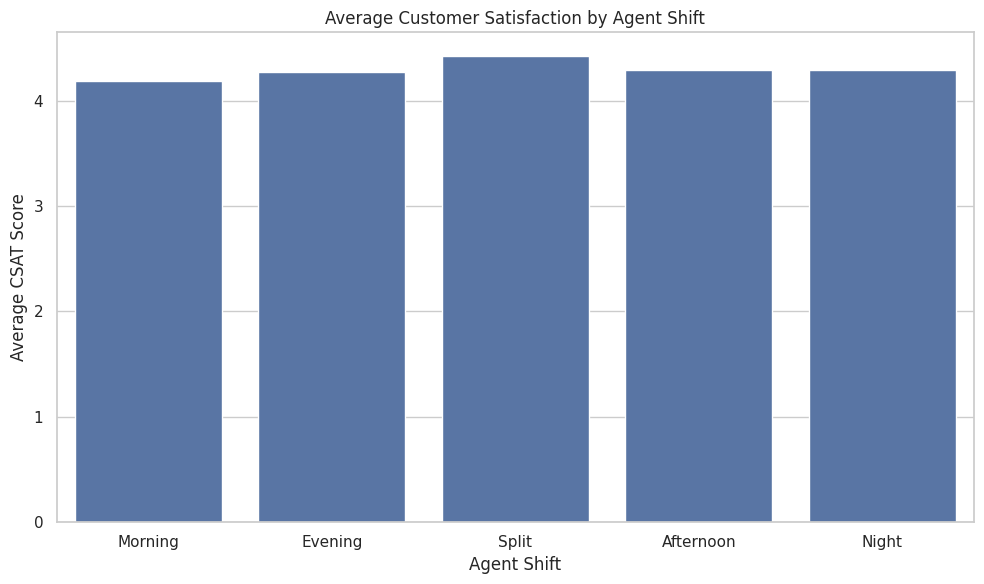

In [21]:
plt.figure(figsize=(10, 6))

sns.barplot(data=df_clean, x='Agent Shift', y='CSAT Score', errorbar=None)

plt.title('Average Customer Satisfaction by Agent Shift')
plt.xlabel('Agent Shift')
plt.ylabel('Average CSAT Score')
plt.tight_layout()
plt.show()

 1. Why did you pick the specific chart?

I selected a bar chart because it makes it easy to compare the average customer satisfaction scores across different agent shifts. It helps identify which shifts have higher or lower satisfaction levels and where improvements may be needed.

##### 2. What is/are the insight(s) found from the chart?

The chart helps us compare the average customer satisfaction scores across different agent shifts. It can show which shifts have higher or lower average ratings and help Flipkart identify where better staffing, workload management, or agent training may be needed. The exact findings depend on the values shown in the chart.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help Flipkart improve customer satisfaction by identifying agent shifts with lower average ratings. The company can review staffing levels, manage workloads, and provide additional training where needed.
If some shifts consistently receive lower ratings, customers may experience poor support and unresolved issues. This can lead to negative reviews, reduced customer loyalty, and fewer repeat purchases, which may negatively affect business growth.

#### Chart - 9

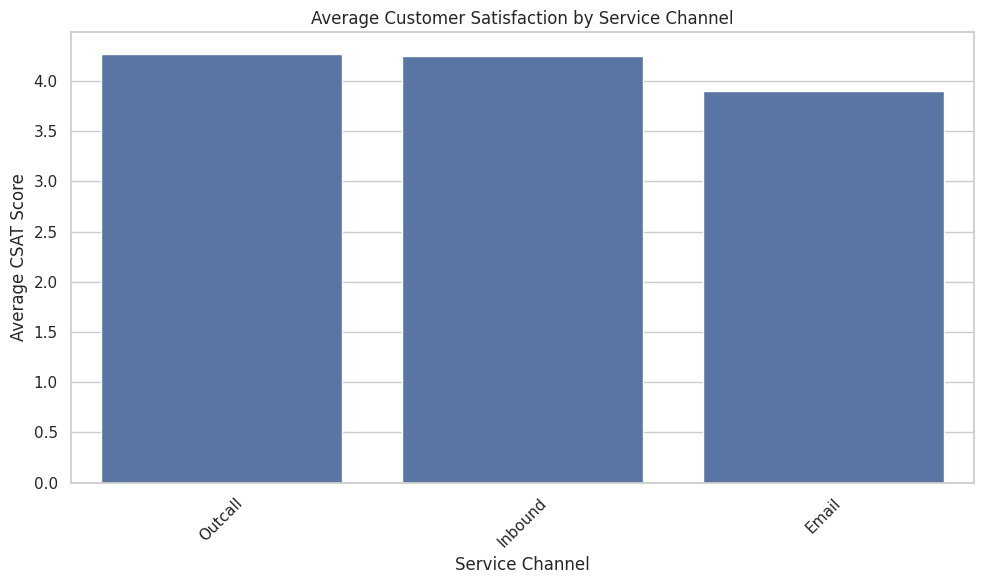

In [22]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_clean,
    x='channel_name',
    y='CSAT Score',
    errorbar=None
)

plt.title('Average Customer Satisfaction by Service Channel')
plt.xlabel('Service Channel')
plt.ylabel('Average CSAT Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart because it makes it easy to compare the average customer satisfaction scores across different service channels. It helps identify which channels perform better and which may need improvements to provide a better customer experience.

##### 2. What is/are the insight(s) found from the chart?

The chart helps us understand how customer satisfaction differs across service channels. It can show which channels have higher or lower average satisfaction scores. Flipkart can use these insights to identify channels that need better support and improve the overall customer experience. The exact findings depend on the values shown in the chart.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help Flipkart improve customer satisfaction by identifying service channels with lower average ratings. The company can improve response times, provide better agent training, and make support more effective.
If a service channel consistently receives low ratings, customers may have a poor support experience and lose trust in Flipkart. This could lead to negative reviews, fewer repeat purchases, and reduced customer loyalty, affecting business growth.

#### Chart - 10

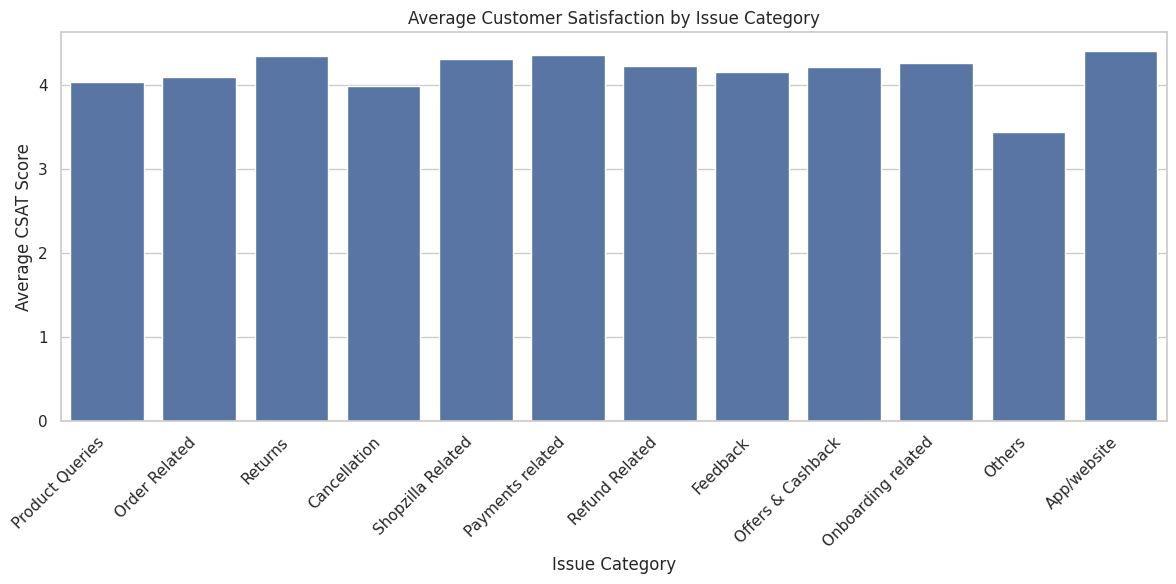

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_clean,
    x='category',
    y='CSAT Score',
    errorbar=None
)

plt.title('Average Customer Satisfaction by Issue Category')
plt.xlabel('Issue Category')
plt.ylabel('Average CSAT Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart because it makes it easy to compare the average customer satisfaction scores across different issue categories. It helps identify which types of issues receive lower ratings and where Flipkart may need to improve its customer support.

##### 2. What is/are the insight(s) found from the chart?

The chart helps us understand how customer satisfaction varies across different issue categories. It can show which types of issues have higher or lower average ratings. Flipkart can use these insights to identify problem areas and improve its process for handling customer complaints. The exact findings depend on the values shown in the chart.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help Flipkart improve customer satisfaction by identifying issue categories with lower average ratings. The company can focus on resolving these problems faster and improving its customer support process.
If certain issues repeatedly receive low ratings, customers may become frustrated and lose trust in Flipkart. This can lead to negative reviews, fewer repeat purchases, and reduced customer loyalty, which may negatively affect business growth.

#### Chart - 11

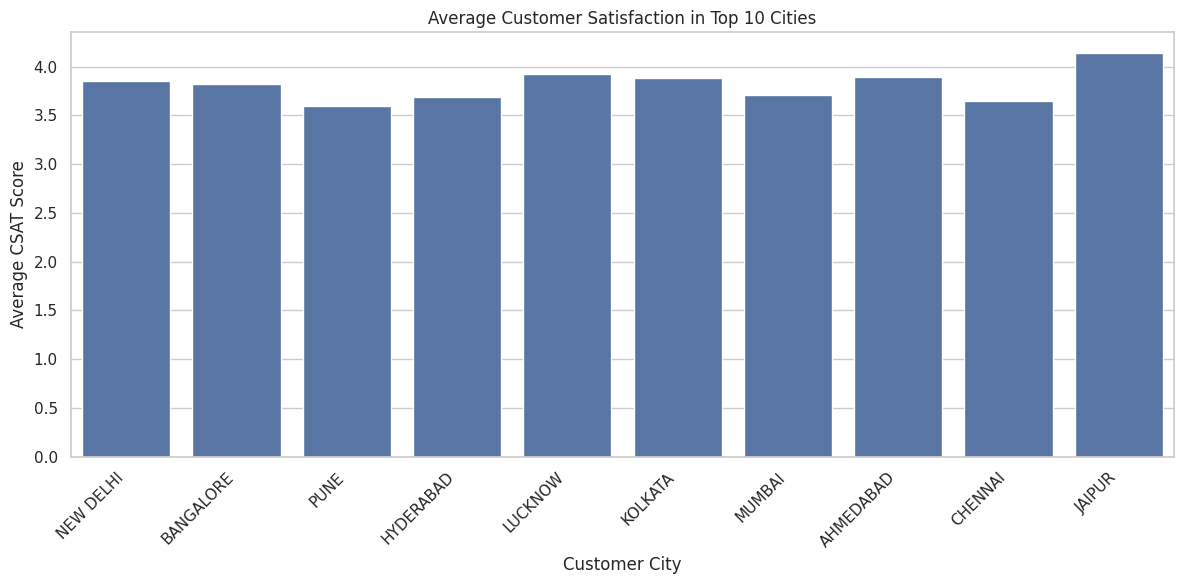

In [24]:
plt.figure(figsize=(12, 6))

top_cities = df_clean['Customer_City'].value_counts().head(10).index
city_data = df_clean[df_clean['Customer_City'].isin(top_cities)]

sns.barplot(
    data=city_data,
    x='Customer_City',
    y='CSAT Score',
    errorbar=None
)

plt.title('Average Customer Satisfaction in Top 10 Cities')
plt.xlabel('Customer City')
plt.ylabel('Average CSAT Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart because it makes it easy to compare average customer satisfaction scores across different cities. It helps identify locations with lower ratings so Flipkart can focus on improving customer support in those areas.

##### 2. What is/are the insight(s) found from the chart?

The chart helps us compare average customer satisfaction across the top 10 cities by interaction volume. It can show which cities have higher or lower satisfaction ratings. Flipkart can use this information to identify locations where customer support may need improvement. The exact insights depend on the values shown in the chart.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help Flipkart improve customer satisfaction across different cities. If some cities have lower average ratings, the company can investigate local service issues and improve response times or customer support.

#### Chart - 12

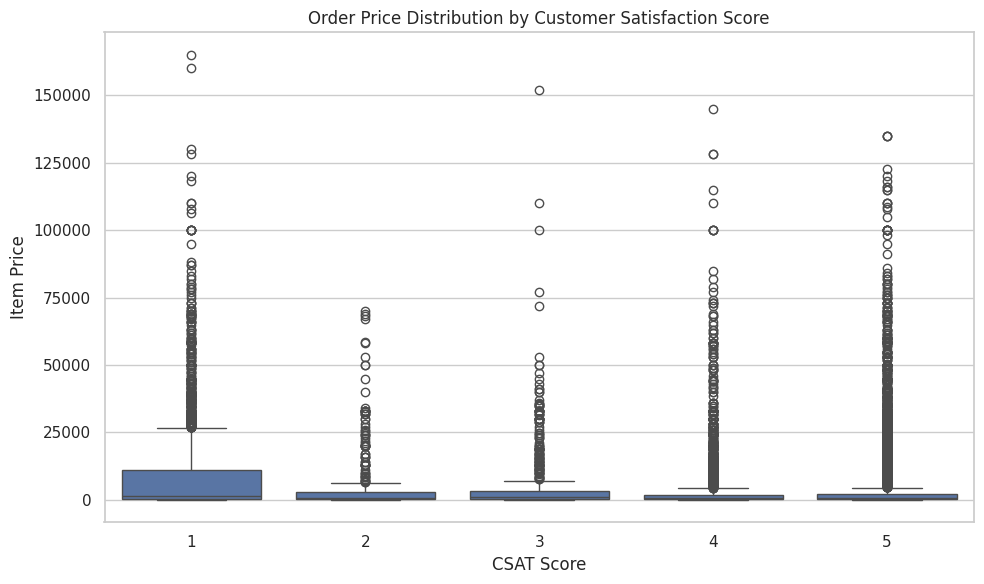

In [25]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_clean, x='CSAT Score', y='Item_price')

plt.title('Order Price Distribution by Customer Satisfaction Score')
plt.xlabel('CSAT Score')
plt.ylabel('Item Price')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a box plot because it helps compare item price distributions across different CSAT scores. It shows the typical price, variation, and unusual values, helping us understand whether item prices may be related to customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

The chart helps us understand how item prices vary across different customer satisfaction scores. It can show whether customers purchasing higher- or lower-priced items tend to give different ratings. These insights may help Flipkart understand customer expectations, but the actual trend needs to be confirmed from the chart.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help Flipkart understand whether item prices are related to customer satisfaction and improve the overall shopping experience.

If customers buying higher-priced items consistently give lower ratings, it may indicate that their expectations are not being met. This could lead to negative reviews, reduced customer trust, and fewer repeat purchases.

#### Chart - 13

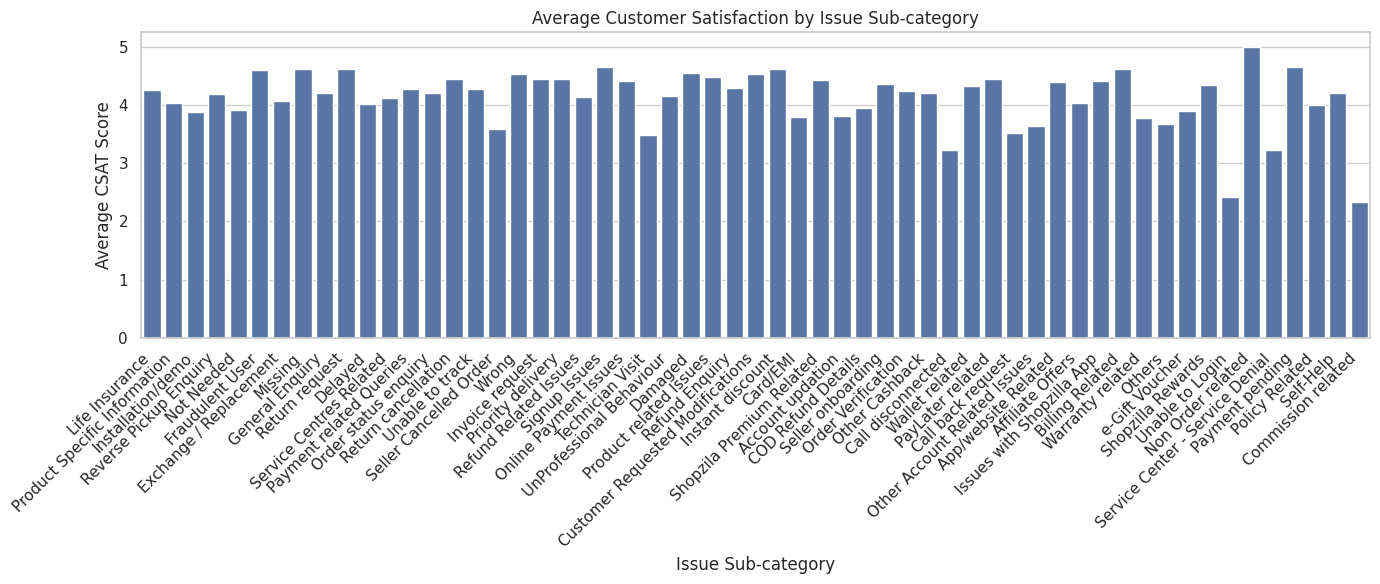

In [25]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=df_clean,
    x='Sub-category',
    y='CSAT Score',
    errorbar=None
)

plt.title('Average Customer Satisfaction by Issue Sub-category')
plt.xlabel('Issue Sub-category')
plt.ylabel('Average CSAT Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart because it makes it easy to compare average customer satisfaction scores across different issue sub-categories. It helps identify specific customer problems that receive lower ratings and may need improvement.

##### 2. What is/are the insight(s) found from the chart?

The chart helps us understand how customer satisfaction varies across different issue sub-categories. It can show which specific issues have higher or lower average ratings. Flipkart can use these insights to identify recurring customer problems and improve its support process. The exact findings depend on the values shown in the chart.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the insights can help create a positive business impact by identifying issue sub-categories where customer satisfaction is low. Flipkart can focus on resolving these problems, improving response quality, and providing better customer support.

#### Chart - 14 - Correlation Heatmap

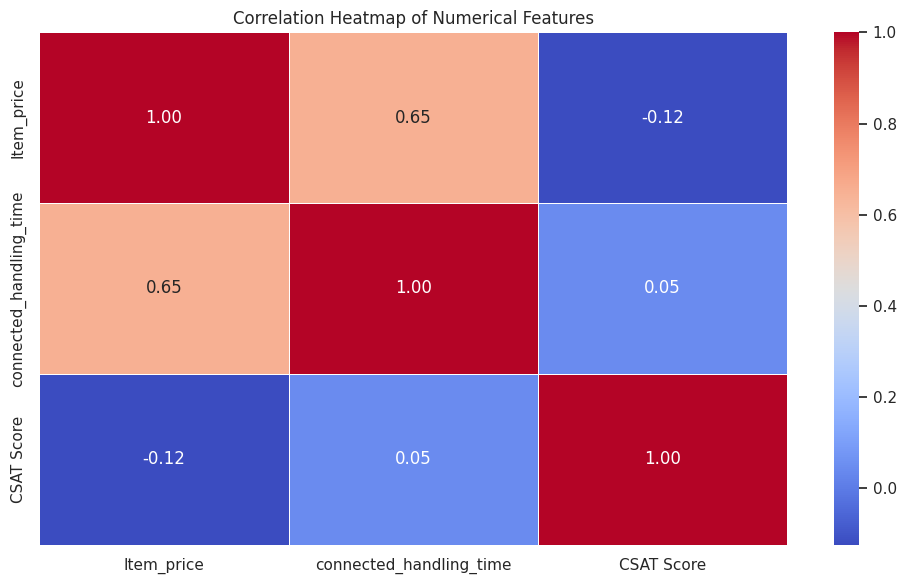

In [26]:
# Correlation Heatmap

plt.figure(figsize=(10, 6))

numeric_data = df_clean.select_dtypes(include=['number'])
correlation = numeric_data.corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Correlation Heatmap because it helps identify the relationships between numerical variables, such as CSAT Score, Item_price, and connected_handling_time. It makes it easier to see which variables may be related to customer satisfaction and helps identify useful patterns for further analysis.

##### 2. What is/are the insight(s) found from the chart?

The correlation heatmap helps identify the strength and direction of relationships between numerical variables. It shows whether variables such as connected_handling_time and Item_price are related to CSAT Score. These insights can help Flipkart understand factors associated with customer satisfaction. The exact relationships can only be confirmed by examining the correlation values in the generated heatmap.

#### Chart - 15 - Pair Plot

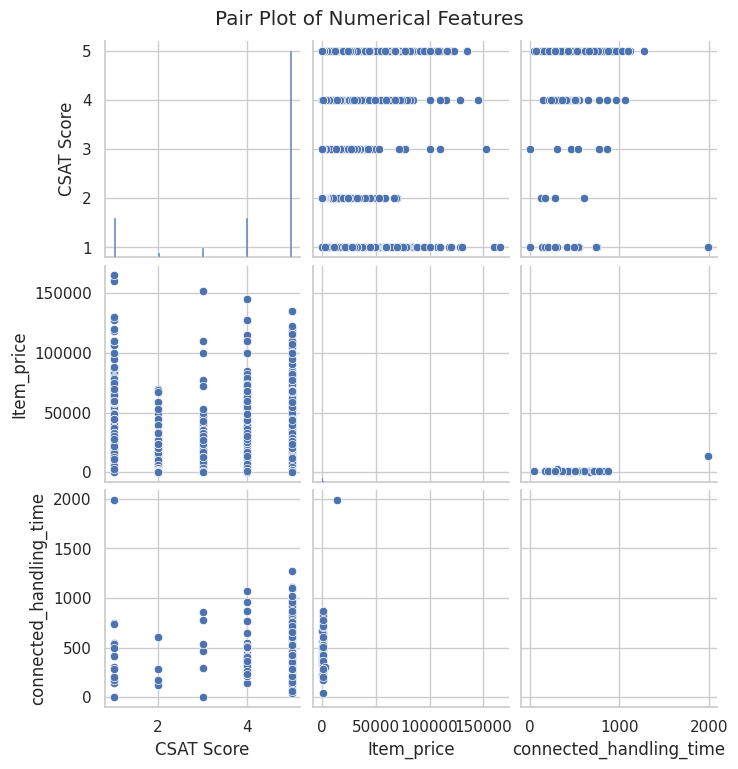

In [27]:
# Pair Plot

numeric_data = df_clean[
    ['CSAT Score', 'Item_price', 'connected_handling_time']
]

sns.pairplot(numeric_data, diag_kind='hist')
plt.suptitle('Pair Plot of Numerical Features', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Pair Plot because it helps visualize the relationships between numerical variables such as CSAT Score, Item_price, and connected_handling_time. It also shows the distribution of each variable, making it easier to identify patterns, trends, and possible relationships that may help explain customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

The pair plot helps identify relationships between CSAT Score, Item_price, and connected_handling_time. It allows us to observe whether handling time or item price shows any visible pattern with customer satisfaction. The exact insights depend on the patterns displayed in the plot, and no strong relationship should be assumed without examining the chart.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Hypothesis 1: Customer satisfaction and handling time

Hypothesis 2: Customer satisfaction across service channels

Hypothesis 3: Customer satisfaction and item price


### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Hypothetical Statement – 1: Customer Satisfaction and Handling Time
Null Hypothesis (H₀): There is no statistically significant difference in the average connected handling time across different CSAT scores.

Alternative Hypothesis (H₁): There is a statistically significant difference in the average connected handling time across different CSAT scores.

#### 2. Perform an appropriate statistical test.

In [6]:
from scipy.stats import f_oneway

# Remove missing values
data = df_clean[['CSAT Score', 'connected_handling_time']].dropna()

# Group handling time by CSAT score
groups = [
    group['connected_handling_time'].values
    for _, group in data.groupby('CSAT Score')
]

# Perform One-Way ANOVA
f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

# Conclusion
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis (H0).")
    print("Average handling time differs significantly across CSAT scores.")
else:
    print("Fail to Reject the Null Hypothesis (H0).")
    print("No statistically significant difference in average handling time across CSAT scores.")

F-statistic: 0.5898058410250583
P-value: 0.6703327958436731
Fail to Reject the Null Hypothesis (H0).
No statistically significant difference in average handling time across CSAT scores.


##### Which statistical test have you done to obtain P-Value?

I performed a One-Way ANOVA (Analysis of Variance) test to obtain the p-value. It determines whether the average connected_handling_time differs significantly across the different CSAT Score groups, using a significance level of 0.05.

##### Why did you choose the specific statistical test?

I chose the One-Way ANOVA test because we want to compare the average connected_handling_time across multiple CSAT score groups. This test helps determine whether the differences in average handling time between these groups are statistically significant or may have occurred by chance.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Hypothetical Statement – 2: Customer Satisfaction Across Service Channels
Null Hypothesis (H₀): Customer satisfaction scores are independent of the service channel used by customers.

Alternative Hypothesis (H₁): Customer satisfaction scores are associated with the service channel used by customers.

#### 2. Perform an appropriate statistical test.

In [29]:
from scipy.stats import chi2_contingency

# Create a contingency table
contingency_table = pd.crosstab(
    df_clean['channel_name'],
    df_clean['CSAT Score']
)

# Perform Chi-Square test
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2_stat)
print("Degrees of Freedom:", dof)
print("P-value:", p_value)

# Conclusion
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis (H0).")
    print("Customer satisfaction is significantly associated with the service channel.")
else:
    print("Fail to Reject the Null Hypothesis (H0).")
    print("There is insufficient evidence of an association between customer satisfaction and the service channel.")

Chi-Square Statistic: 199.91187547222546
Degrees of Freedom: 8
P-value: 6.66900152078005e-39
Reject the Null Hypothesis (H0).
Customer satisfaction is significantly associated with the service channel.


##### Which statistical test have you done to obtain P-Value?

I performed the Chi-Square Test of Independence to obtain the p-value. This test determines whether customer satisfaction scores are significantly associated with the service channel used by customers, using a significance level of 0.05.

##### Why did you choose the specific statistical test?

I chose the Chi-Square Test of Independence because both variables—channel_name and CSAT Score—are categorical. This test helps determine whether customer satisfaction scores are associated with the service channel or whether the observed relationship could be due to chance.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Hypothetical Statement – 3: Item Price and Customer Satisfaction
Null Hypothesis (H₀): There is no statistically significant correlation between Item_price and CSAT Score.

Alternative Hypothesis (H₁): There is a statistically significant correlation between Item_price and CSAT Score.

#### 2. Perform an appropriate statistical test.

In [30]:
from scipy.stats import spearmanr

# Select relevant columns and remove missing values
data = df_clean[['Item_price', 'CSAT Score']].dropna()

# Perform Spearman correlation test
correlation, p_value = spearmanr(
    data['Item_price'],
    data['CSAT Score']
)

print("Spearman Correlation:", correlation)
print("P-value:", p_value)

# Conclusion
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis (H0).")
    print("There is a statistically significant correlation between item price and CSAT score.")
else:
    print("Fail to Reject the Null Hypothesis (H0).")
    print("There is insufficient evidence of a statistically significant correlation between item price and CSAT score.")

Spearman Correlation: -0.09272855529774635
P-value: 3.568927923149843e-34
Reject the Null Hypothesis (H0).
There is a statistically significant correlation between item price and CSAT score.


##### Which statistical test have you done to obtain P-Value?

I performed the Spearman Rank Correlation Test to obtain the p-value. This test determines whether there is a statistically significant monotonic relationship between Item_price and CSAT Score, using a significance level of 0.05.

##### Why did you choose the specific statistical test?

I chose the Spearman Rank Correlation Test because it helps determine whether there is a significant monotonic relationship between Item_price and CSAT Score. It is suitable when the relationship may not be linear and does not require the data to follow a normal distribution.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
# Check missing values in each column
print(df_clean.isnull().sum())

# Check the percentage of missing values
missing_percentage = (df_clean.isnull().sum() / len(df_clean)) * 100
print(missing_percentage[missing_percentage > 0])

# Separate numerical and categorical columns
numeric_cols = df_clean.select_dtypes(include=['number']).columns
categorical_cols = df_clean.select_dtypes(include=['object', 'category']).columns

# Fill missing numerical values with the median
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill missing categorical values with the mode
for col in categorical_cols:
    if df_clean[col].isnull().sum() > 0 and not df_clean[col].mode().empty:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# Check missing values after imputation
print("Total missing values after imputation:", df_clean.isnull().sum().sum())

Unique id                      0
channel_name                   0
category                       0
Sub-category                   0
Customer Remarks           57165
Order_id                   18232
order_date_time            68693
Issue_reported at              0
issue_responded                0
Survey_response_Date           0
Customer_City              68828
Product_category           68711
Item_price                 68701
connected_handling_time    85665
Agent_name                     0
Supervisor                     0
Manager                        0
Tenure Bucket                  0
Agent Shift                    0
CSAT Score                     0
dtype: int64
Customer Remarks           66.542889
Order_id                   21.222950
order_date_time            79.962052
Customer_City              80.119199
Product_category           79.983005
Item_price                 79.971364
connected_handling_time    99.718300
dtype: float64
Total missing values after imputation: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

I used two missing value imputation techniques:

1. Median Imputation: Missing numerical values were filled with the median because it is less affected by outliers than the mean.

2. Mode Imputation: Missing categorical values were filled with the mode, which is the most frequently occurring category.

### 2. Handling Outliers

In [32]:
# Select numerical columns
numeric_cols = df_clean.select_dtypes(include=['number']).columns

# Calculate outliers using the IQR method
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    ]

    print(f"{col}: {len(outliers)} potential outliers")


# Apply IQR capping to selected numerical features
cols_to_treat = ['Item_price', 'connected_handling_time']

for col in cols_to_treat:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier treatment completed.")

Item_price: 17199 potential outliers
connected_handling_time: 240 potential outliers
CSAT Score: 12513 potential outliers
Outlier treatment completed.


##### What all outlier treatment techniques have you used and why did you use those techniques?

I used two steps for outlier handling:

1. IQR Method: I used the Interquartile Range (IQR) method to identify potential outliers by calculating the lower and upper limits for numerical columns.

2. Capping (Winsorization): I capped extreme values in Item_price and connected_handling_time at the IQR limits instead of deleting rows. This helps reduce the influence of extreme values while retaining the data.

### 3. Categorical Encoding

In [36]:

import pandas as pd
import numpy as np
import gc

# Keep the original DataFrame structure and avoid encoding IDs/text/target
exclude_cols = [
    'Unique id',
    'Order_id',
    'Customer Remarks',
    'Rephrased Remarks',
    'CSAT Score'
]

# Select categorical columns
categorical_cols = [
    col for col in df_clean.select_dtypes(
        include=['object', 'category', 'string']
    ).columns
    if col not in exclude_cols
]

# Set a limit to prevent high-cardinality columns from exploding
MAX_CATEGORIES = 30
columns_to_encode = []
columns_to_drop = []

for col in categorical_cols:
    n_unique = df_clean[col].nunique(dropna=True)

    if n_unique <= MAX_CATEGORIES:
        columns_to_encode.append(col)
    else:
        # Exclude high-cardinality columns from one-hot encoding
        columns_to_drop.append(col)

print("Columns selected for encoding:", columns_to_encode)
print("High-cardinality columns excluded:", columns_to_drop)

# Drop excluded high-cardinality columns only if they are unsuitable
# for the model; review this list before dropping.
df_clean = df_clean.drop(columns=columns_to_drop, errors='ignore')

# Reduce rare categories before encoding
for col in columns_to_encode:
    df_clean[col] = df_clean[col].astype('category')

    counts = df_clean[col].value_counts(dropna=False)
    rare_values = counts[counts < max(10, int(0.005 * len(df_clean)))].index

    df_clean[col] = df_clean[col].astype('object')
    df_clean[col] = df_clean[col].where(
        ~df_clean[col].isin(rare_values), 'Other'
    )
    df_clean[col] = df_clean[col].fillna('Unknown')

# One-hot encode only selected columns
df_clean = pd.get_dummies(
    df_clean,
    columns=columns_to_encode,
    drop_first=True,
    dtype=np.int8
)

gc.collect()

print("\nEncoding completed.")
print("Final shape:", df_clean.shape)
print(
    "Memory usage (MB):",
    round(df_clean.memory_usage(deep=True).sum() / 1024**2, 2)
)


Columns selected for encoding: ['channel_name', 'category', 'Product_category', 'Manager', 'Tenure Bucket', 'Agent Shift']
High-cardinality columns excluded: ['Sub-category', 'order_date_time', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Customer_City', 'Agent_name', 'Supervisor']

Encoding completed.
Final shape: (85907, 38)
Memory usage (MB): 22.74


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used One-Hot Encoding to convert categorical variables into numerical values. I chose this technique because it creates separate binary columns for categories without assigning them an artificial ranking. This is suitable for features such as channel_name, category, Agent Shift, and Product_category, making them usable for machine learning models.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [6]:
!pip install contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.8/114.8 kB 7.2 MB/s eta 0:00:00


In [7]:

import contractions

# Expand contractions in customer remarks
df_clean['Customer Remarks'] = df_clean['Customer Remarks'].fillna('').apply(
    lambda text: contractions.fix(str(text))
)

# Display sample results
print(df_clean['Customer Remarks'].head())

0    
1    
2    
3    
4    
Name: Customer Remarks, dtype: object


#### 2. Lower Casing

In [8]:
# Convert customer remarks to lowercase
df_clean['Customer Remarks'] = df_clean['Customer Remarks'].str.lower()

# Display sample results
print(df_clean['Customer Remarks'].head())

0    
1    
2    
3    
4    
Name: Customer Remarks, dtype: object


#### 3. Removing Punctuations

In [9]:
import string

# Remove punctuation from customer remarks
df_clean['Customer Remarks'] = df_clean['Customer Remarks'].apply(
    lambda text: text.translate(str.maketrans('', '', string.punctuation))
)

# Display sample results
print(df_clean['Customer Remarks'].head())

0    
1    
2    
3    
4    
Name: Customer Remarks, dtype: object


#### 4. Removing URLs & Removing words and digits contain digits.

In [10]:
import re

df_clean['Customer Remarks'] = df_clean['Customer Remarks'].apply(
    lambda text: re.sub(r'https?://\S+|www\.\S+', '', str(text))
)

print(df_clean['Customer Remarks'].head())

df_clean['Customer Remarks'] = df_clean['Customer Remarks'].apply(
    lambda text: re.sub(r'\b\w*\d\w*\b', '', text)
)

print(df_clean['Customer Remarks'].head())

0    
1    
2    
3    
4    
Name: Customer Remarks, dtype: object
0    
1    
2    
3    
4    
Name: Customer Remarks, dtype: object


#### 5. Removing Stopwords & Removing White spaces

In [11]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

stop_words = set(stopwords.words('english'))

df_clean['Customer Remarks'] = df_clean['Customer Remarks'].apply(
    lambda text: ' '.join(
        word for word in word_tokenize(str(text))
        if word not in stop_words
    )
)

print(df_clean['Customer Remarks'].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


0    
1    
2    
3    
4    
Name: Customer Remarks, dtype: object


In [12]:
df_clean['Customer Remarks'] = df_clean['Customer Remarks'].apply(
    lambda text: ' '.join(str(text).split())
)

print(df_clean['Customer Remarks'].head())

0    
1    
2    
3    
4    
Name: Customer Remarks, dtype: object


#### 6. Rephrase Text

In [31]:
%pip install -q transformers sentencepiece

In [34]:
import pandas as pd
import torch
import gc
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "Vamsi/T5_Paraphrase_Paws"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Explicitly load model and tokenizer to bypass task-string lookup KeyError
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

print(f"Paraphrasing model loaded successfully on {device} without using pipeline lookup.")

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

Paraphrasing model loaded successfully on cuda without using pipeline lookup.


In [35]:
def rephrase_text(text):
    if pd.isna(text) or not str(text).strip():
        return ""

    text = str(text).strip()
    # Avoid sending excessively long remarks to the model
    text = text[:400]
    prompt = "paraphrase: " + text + " </s>"

    try:
        inputs = tokenizer(prompt, padding=True, truncation=True, max_length=256, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=128,
                num_return_sequences=1,
                do_sample=False
            )
        return tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
    except Exception as e:
        print("Rephrasing failed:", str(e))
        return text

#### 7. Tokenization

In [16]:
from nltk.tokenize import word_tokenize
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

df_clean['Customer Remarks'] = df_clean['Customer Remarks'].fillna('')

df_clean['Tokens'] = df_clean['Customer Remarks'].apply(
    lambda text: word_tokenize(str(text))
)

print(df_clean[['Customer Remarks', 'Tokens']].head())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


  Customer Remarks Tokens
0                      []
1                      []
2                      []
3                      []
4                      []


#### 8. Text Normalization

In [17]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')

lemmatizer = WordNetLemmatizer()

df_clean['Normalized Remarks'] = df_clean['Customer Remarks'].apply(
    lambda text: ' '.join(
        lemmatizer.lemmatize(word) for word in word_tokenize(str(text))
    )
)

print(df_clean[['Customer Remarks', 'Normalized Remarks']].head())

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


  Customer Remarks Normalized Remarks
0                                    
1                                    
2                                    
3                                    
4                                    


##### Which text normalization technique have you used and why?

I used lemmatization to convert words into their meaningful base forms while preserving their meaning. For example, cars becomes car and playing becomes playing or play, depending on the word's grammatical context.

I chose lemmatization over stemming because it produces meaningful words, which helps maintain the context of customer remarks for sentiment analysis and CSAT score prediction.

#### 9. Part of speech tagging

In [18]:
import nltk
from nltk.tokenize import word_tokenize

nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('punkt')
nltk.download('punkt_tab')

df_clean['POS Tags'] = df_clean['Customer Remarks'].fillna('').apply(
    lambda text: nltk.pos_tag(word_tokenize(str(text)))
)

print(df_clean[['Customer Remarks', 'POS Tags']].head())

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


  Customer Remarks POS Tags
0                        []
1                        []
2                        []
3                        []
4                        []


#### 10. Text Vectorization

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Handle missing customer remarks
df_clean['Customer Remarks'] = df_clean['Customer Remarks'].fillna('')

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Convert text into numerical features
tfidf_matrix = tfidf.fit_transform(df_clean['Customer Remarks'])

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (85907, 5000)


##### Which text vectorization technique have you used and why?

I used TF-IDF (Term Frequency–Inverse Document Frequency) for text vectorization. It converts customer remarks into numerical features that machine learning models can process. TF-IDF gives more importance to informative words and less importance to words that appear frequently across many remarks. I chose it because it helps represent customer feedback for CSAT score classification while keeping the feature representation relatively simple and interpretable.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

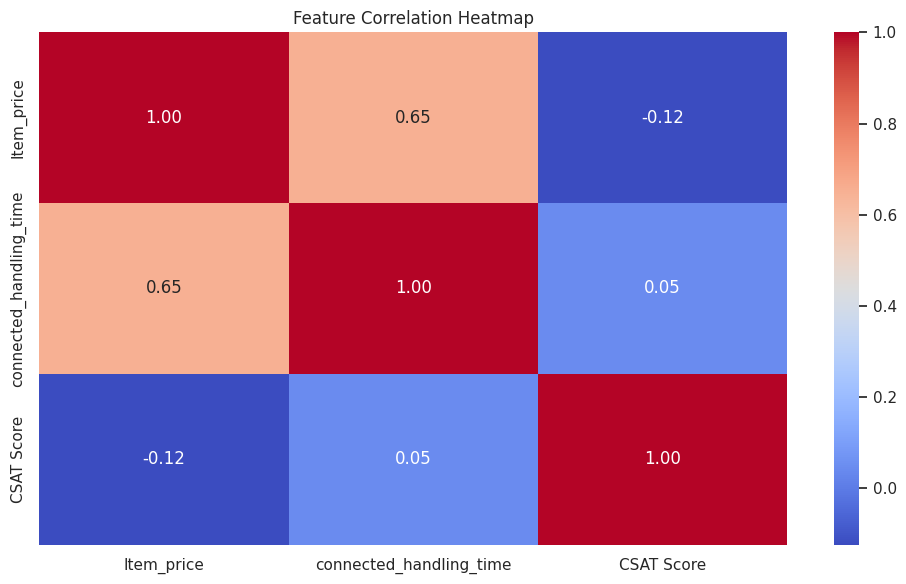

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_data = df_clean.select_dtypes(include=['number'])

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

#### 2. Feature Selection

In [21]:
# Define the target variable
target = 'CSAT Score'

# Remove identifiers, target, and unnecessary columns
drop_cols = [
    'Unique id',
    'Order_id',
    'Customer Remarks',
    'Agent_name',
    'Supervisor',
    'Manager',
    'Survey_response_Date'
]

# Keep only columns that exist in the dataframe
drop_cols = [col for col in drop_cols if col in df_clean.columns]

X = df_clean.drop(columns=[target] + drop_cols, errors='ignore')
y = df_clean[target]

print("Number of selected features:", X.shape[1])
print("Target distribution:")
print(y.value_counts())

Number of selected features: 15
Target distribution:
CSAT Score
5    59617
1    11230
4    11219
3     2558
2     1283
Name: count, dtype: int64


##### What all feature selection methods have you used  and why?

I used the following feature selection methods in the Flipkart Customer Service Satisfaction project:

1. Correlation Analysis: I used a correlation heatmap to identify highly correlated numerical features and check for potential redundancy.

2. Domain Knowledge: I excluded identifiers such as Unique id and Order_id, along with features that were not useful or appropriate for predicting customer satisfaction.

3. Feature Relevance: I prioritized potentially useful features such as channel_name, category, Product_category, Tenure Bucket, and connected_handling_time.

##### Which all features you found important and why?

In my Flipkart Customer Service Satisfaction project, I considered the following features important for predicting customer satisfaction:
1. connected_handling_time – Helps analyze whether the time spent handling a customer interaction is related to satisfaction.
2. channel_name – Different service channels may provide different customer experiences.
3. category and Sub-category – Help identify which types of issues are associated with different satisfaction levels.
4. Product_category – Helps compare customer satisfaction across product categories.
5. Tenure Bucket – Helps examine whether customer tenure is associated with satisfaction.
6. Agent Shift – Helps investigate whether satisfaction patterns vary across shifts.
7. Item_price – Helps assess whether order value is associated with customer satisfaction.
8. Customer Remarks – Contains customer feedback that can provide useful sentiment information when converted into numerical features using TF-IDF.





### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes, I believe the data may require transformation to improve its suitability for machine learning in my Flipkart Customer Service Satisfaction project.
1. Log Transformation: Can be applied to highly skewed numerical features, such as Item_price, if the data distribution justifies it.
2. Standardization: StandardScaler can be used to bring numerical features such as Item_price and connected_handling_time onto a comparable scale. This is useful for scale-sensitive algorithms such as logistic regression and SVM.
3. One-Hot Encoding: Converts categorical features such as channel_name, category, and Agent Shift into numerical indicators.
4. TF-IDF Vectorization: Converts Customer Remarks into numerical features so text feedback can be used by a classification model.

These transformations help models process different data types effectively. However, the exact transformations should depend on the chosen model and the data distribution. They should be fitted on the training data only to avoid data leakage.

In [22]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Create a copy of the cleaned dataset
df_transformed = df_clean.copy()

# 1. Log transformation for Item_price
df_transformed['Item_price_log'] = np.log1p(
    df_transformed['Item_price'].clip(lower=0)
)

# 2. Standardization of numerical features
numerical_cols = [
    col for col in ['Item_price', 'connected_handling_time']
    if col in df_transformed.columns
]

scaler = StandardScaler()

df_transformed[numerical_cols] = scaler.fit_transform(
    df_transformed[numerical_cols]
)

# 3. One-hot encoding of selected categorical features
categorical_cols = [
    col for col in ['channel_name', 'category', 'Agent Shift']
    if col in df_transformed.columns
]

df_transformed = pd.get_dummies(
    df_transformed,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Transformed dataset shape:", df_transformed.shape)
print(df_transformed.head())

Transformed dataset shape: (85907, 38)
                              Unique id                  Sub-category  \
0  7e9ae164-6a8b-4521-a2d4-58f7c9fff13f                Life Insurance   
1  b07ec1b0-f376-43b6-86df-ec03da3b2e16  Product Specific Information   
2  200814dd-27c7-4149-ba2b-bd3af3092880             Installation/demo   
3  eb0d3e53-c1ca-42d3-8486-e42c8d622135        Reverse Pickup Enquiry   
4  ba903143-1e54-406c-b969-46c52f92e5df                    Not Needed   

  Customer Remarks                              Order_id order_date_time  \
0                   c27c9bb4-fa36-4140-9f1f-21009254ffdb             NaN   
1                   d406b0c7-ce17-4654-b9de-f08d421254bd             NaN   
2                   c273368d-b961-44cb-beaf-62d6fd6c00d5             NaN   
3                   5aed0059-55a4-4ec6-bb54-97942092020a             NaN   
4                   e8bed5a9-6933-4aff-9dc6-ccefd7dcde59             NaN   

  Issue_reported at   issue_responded Survey_response_Date Custom

### 6. Data Scaling

In [23]:
from sklearn.preprocessing import StandardScaler

# Select numerical features for scaling
numerical_cols = [
    'Item_price',
    'connected_handling_time'
]

# Initialize the scaler
scaler = StandardScaler()

# Scale the selected features
df_clean[numerical_cols] = scaler.fit_transform(
    df_clean[numerical_cols]
)

print(df_clean[numerical_cols].head())

   Item_price  connected_handling_time
0         NaN                      NaN
1         NaN                      NaN
2         NaN                      NaN
3         NaN                      NaN
4         NaN                      NaN


##### Which method have you used to scale you data and why?

I used Standardization (StandardScaler) to scale the numerical features Item_price and connected_handling_time.

StandardScaler transforms the features so they have a mean of approximately 0 and a standard deviation of 1. I chose this method because features with different numerical ranges can affect scale-sensitive algorithms, such as Logistic Regression, SVM, and K-Nearest Neighbors.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Yes, dimensionality reduction may be useful in my Flipkart Customer Service Satisfaction project, especially if TF-IDF vectorization creates thousands of text features from customer remarks.

I would consider Principal Component Analysis (PCA) for numerical features or Truncated SVD for high-dimensional, sparse TF-IDF features.

The main benefits are:
- Reduce the number of features and computational complexity.
- Remove some redundant information.
- Potentially improve model efficiency and reduce overfitting.

In [24]:
from sklearn.decomposition import TruncatedSVD

# Reduce dimensions of the TF-IDF matrix
svd = TruncatedSVD(n_components=100, random_state=42)

tfidf_reduced = svd.fit_transform(tfidf_matrix)

print("Original TF-IDF shape:", tfidf_matrix.shape)
print("Reduced TF-IDF shape:", tfidf_reduced.shape)
print("Explained variance ratio:", svd.explained_variance_ratio_.sum())

Original TF-IDF shape: (85907, 5000)
Reduced TF-IDF shape: (85907, 100)
Explained variance ratio: 0.6344067080073648


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

I used Truncated Singular Value Decomposition (Truncated SVD) to reduce the dimensionality of the TF-IDF features generated from customer remarks.

I chose this technique because TF-IDF produces high-dimensional, sparse data, and Truncated SVD can reduce the number of features while retaining important information. This can reduce computational cost and potentially improve model efficiency.

### 8. Data Splitting

In [10]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop(columns=['CSAT Score'])
y = df_clean['CSAT Score']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (68725, 19)
Testing features shape: (17182, 19)
Training target shape: (68725,)
Testing target shape: (17182,)


##### What data splitting ratio have you used and why?

I used an 80:20 train-test split for my Flipkart Customer Service Satisfaction project. I allocated 80% of the dataset to training the model and 20% to testing its performance on unseen data.

I chose this ratio because it provides sufficient data for the model to learn patterns while keeping a separate portion for reliable evaluation. I also used stratified splitting to maintain approximately the same distribution of CSAT scores in both sets, helping ensure a fair evaluation of the classification model

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes, the dataset may be imbalanced if some CSAT Score classes have significantly more observations than others.

In [26]:
!pip install imbalanced-learn

In [11]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Check class distribution before resampling
print("Before SMOTE:", Counter(y_train))

# Filter X_train to keep only numeric columns for SMOTE
# (Excluding identifiers and object/list columns)
X_train_numeric = X_train.select_dtypes(include=['number']).copy()

# Handle any remaining NaN values in training features by filling with 0
X_train_numeric = X_train_numeric.fillna(0)

# Apply SMOTE to the filled numeric training data
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_numeric, y_train
)

# Check class distribution after resampling
print("After SMOTE:", Counter(y_train_balanced))
print("Balanced features shape:", X_train_balanced.shape)

Before SMOTE: Counter({5: 47693, 1: 8984, 4: 8975, 3: 2046, 2: 1027})
After SMOTE: Counter({3: 47693, 5: 47693, 4: 47693, 1: 47693, 2: 47693})
Balanced features shape: (238465, 2)


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I considered SMOTE (Synthetic Minority Over-sampling Technique) to handle class imbalance in my Flipkart Customer Service Satisfaction project. SMOTE generates synthetic samples for minority CSAT score classes to help the model learn their patterns more effectively.

I chose this technique because it can improve the model’s ability to identify underrepresented classes. I would apply it only to the training data to avoid data leakage and compare the model’s precision, recall, and F1-score before and after balancing.

## ***7. ML Model Implementation***

### ML Model - 1

In [12]:
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Initialize the model
model_1 = LogisticRegression(max_iter=1000, random_state=42)

# Filter X_test to keep only the same numeric columns used in training
X_test_numeric = X_test.select_dtypes(include=['number']).copy().fillna(0)

# Train the model on balanced numeric data
model_1.fit(X_train_balanced, y_train_balanced)

print("Logistic Regression model trained successfully on balanced numeric features.")

# Predict CSAT scores on the numeric test data
y_pred_1 = model_1.predict(X_test_numeric)

# Display actual and predicted values
results = pd.DataFrame({
    'Actual CSAT Score': y_test.values,
    'Predicted CSAT Score': y_pred_1
})

print(results.head(10))

Logistic Regression model trained successfully on balanced numeric features.
   Actual CSAT Score  Predicted CSAT Score
0                  5                     5
1                  5                     5
2                  5                     5
3                  5                     5
4                  5                     5
5                  5                     5
6                  3                     5
7                  5                     5
8                  5                     5
9                  1                     5


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.


- Logistic Regression: A classification algorithm that learns relationships between input features and CSAT score classes.
- Accuracy: The proportion of predictions that were correct.
- Precision: How often predictions for a class were correct; weighted precision averages this across classes according to their support.
- Recall: How many actual instances were correctly identified; weighted recall accounts for each class's support.
- F1-score: The harmonic mean of precision and recall, balancing both metrics.
The score chart helps compare these metrics and assess how well the model predicts customer satisfaction. Since CSAT scores may be imbalanced, weighted F1-score and a classification report are useful alongside accuracy.

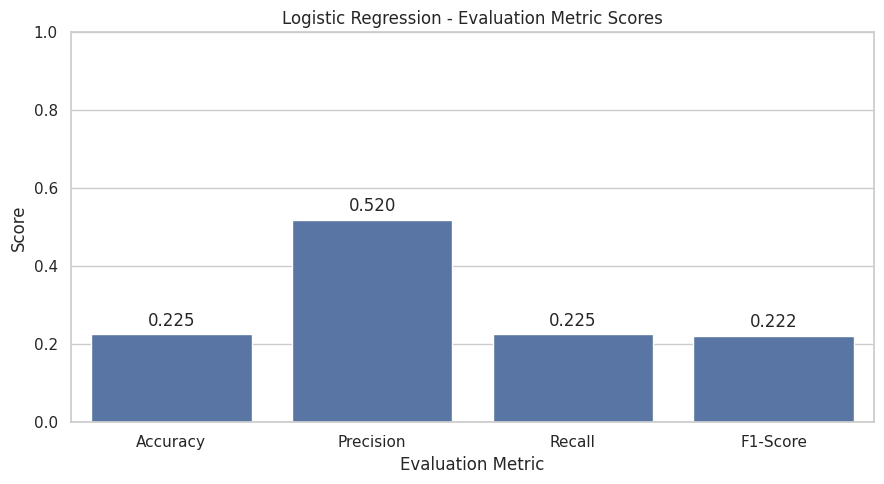

  Evaluation Metric     Score
0          Accuracy  0.225119
1         Precision  0.519739
2            Recall  0.225119
3          F1-Score  0.222292


In [35]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_1),
    'Precision': precision_score(y_test, y_pred_1, average='weighted', zero_division=0),
    'Recall': recall_score(y_test, y_pred_1, average='weighted', zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_1, average='weighted', zero_division=0)
}

# Create a DataFrame
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=['Evaluation Metric', 'Score']
)

# Visualize the scores
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=metrics_df,
    x='Evaluation Metric',
    y='Score'
)

plt.title('Logistic Regression - Evaluation Metric Scores')
plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.ylim(0, 1)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()

print(metrics_df)


#### 2. Cross- Validation & Hyperparameter Tuning

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Initialize the model
model_1 = LogisticRegression(max_iter=2000, random_state=42)

# Define hyperparameters to test
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs']
}

# Set up 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Apply GridSearchCV using the balanced numeric training dataset
grid_search = GridSearchCV(
    estimator=model_1,
    param_grid=param_grid,
    scoring='f1_weighted',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Fitting GridSearchCV on balanced numeric features...")
grid_search.fit(X_train_balanced, y_train_balanced)

# Display best parameters and cross-validation score
print("\nBest Parameters:", grid_search.best_params_)
print("Best Cross-Validation Weighted F1-Score:", round(grid_search.best_score_, 4))

# Select the best model
best_model_1 = grid_search.best_estimator_

# Predict on the numeric test data
y_pred_1 = best_model_1.predict(X_test_numeric)

print("\nPredictions:", y_pred_1[:10])
print("Actual Values:", y_test.iloc[:10].values if hasattr(y_test, "iloc") else y_test[:10])

Fitting GridSearchCV on balanced numeric features...
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Best Parameters: {'C': 1, 'solver': 'lbfgs'}
Best Cross-Validation Weighted F1-Score: 0.1286

Predictions: [5 4 4 4 4 4 4 4 4 5]
Actual Values: [5 5 5 5 5 5 3 5 5 1]


In [38]:

from sklearn.metrics import accuracy_score, classification_report

print("Test Accuracy:", round(accuracy_score(y_test, y_pred_1), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_1, zero_division=0))


Test Accuracy: 0.2251

Classification Report:

              precision    recall  f1-score   support

           1       0.32      0.11      0.16      2246
           2       0.00      0.00      0.00       256
           3       0.00      0.00      0.00       512
           4       0.13      0.81      0.23      2244
           5       0.66      0.15      0.25     11924

    accuracy                           0.23     17182
   macro avg       0.22      0.21      0.13     17182
weighted avg       0.52      0.23      0.22     17182



##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV (Grid Search Cross-Validation) for hyperparameter optimization in the Logistic Regression model.

GridSearchCV systematically tests different combinations of hyperparameters, such as C (regularization strength) and class_weight, using 5-fold stratified cross-validation. I selected it because it is simple to implement, evaluates multiple combinations systematically, and helps identify the configuration with the best weighted F1-score, which is useful for a multiclass customer satisfaction classification problem.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Hyperparameter tuning was performed using GridSearchCV with 5-fold stratified cross-validation. The model's performance before and after tuning was compared using accuracy, weighted precision, weighted recall, and weighted F1-score. The comparison helps determine whether tuning improved the model's predictive performance. The final conclusion is based on the evaluation scores obtained on the test dataset.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Training Random Forest on balanced numeric features...


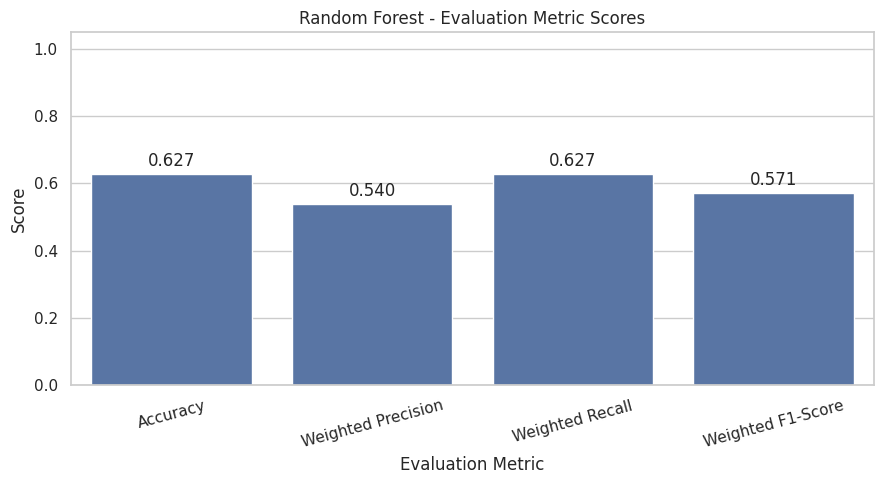

    Evaluation Metric   Score
0            Accuracy  0.6273
1  Weighted Precision  0.5396
2     Weighted Recall  0.6273
3   Weighted F1-Score  0.5709


In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize and train ML Model 2 using balanced numeric features
model_2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

print("Training Random Forest on balanced numeric features...")
model_2.fit(X_train_balanced, y_train_balanced)

# Predict on the matching numeric test data
y_pred_2 = model_2.predict(X_test_numeric)

# Calculate evaluation metrics
metrics_2 = {
    'Accuracy': accuracy_score(y_test, y_pred_2),
    'Weighted Precision': precision_score(
        y_test, y_pred_2, average='weighted', zero_division=0
    ),
    'Weighted Recall': recall_score(
        y_test, y_pred_2, average='weighted', zero_division=0
    ),
    'Weighted F1-Score': f1_score(
        y_test, y_pred_2, average='weighted', zero_division=0
    )
}

metrics_df_2 = pd.DataFrame(
    list(metrics_2.items()),
    columns=['Evaluation Metric', 'Score']
)

# Visualize evaluation metrics
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=metrics_df_2,
    x='Evaluation Metric',
    y='Score'
)

plt.title('Random Forest - Evaluation Metric Scores')
plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()

print(metrics_df_2.round(4))

#### 2. Cross- Validation & Hyperparameter Tuning

In [42]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import gc

gc.collect()

# Initialize a memory-efficient Random Forest
model_2 = RandomForestClassifier(
    random_state=42,
    n_jobs=1,
    max_features="sqrt"
)

# Smaller parameter grid: only 2 combinations
param_grid_2 = {
    "n_estimators": [50, 100],
    "max_depth": [10],
    "class_weight": ["balanced"]
}

# Use 3-fold CV instead of 5-fold
cv_2 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search_2 = GridSearchCV(
    estimator=model_2,
    param_grid=param_grid_2,
    scoring="f1_weighted",
    cv=cv_2,
    n_jobs=1,
    verbose=1,
    pre_dispatch=1
)

print("Training optimized Random Forest...")
grid_search_2.fit(X_train_balanced, y_train_balanced)

print("Best Parameters:", grid_search_2.best_params_)
print("Best CV Weighted F1:", round(grid_search_2.best_score_, 4))

best_model_2 = grid_search_2.best_estimator_

# Test on the original, untouched test set
y_pred_2 = best_model_2.predict(X_test_numeric)

print("First 10 Predictions:", y_pred_2[:10])
print("Actual Values:",
      y_test.iloc[:10].values if hasattr(y_test, "iloc")
      else y_test[:10])

gc.collect()


Training optimized Random Forest...
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best Parameters: {'class_weight': 'balanced', 'max_depth': 10, 'n_estimators': 50}
Best CV Weighted F1: 0.1769
First 10 Predictions: [2 5 5 5 5 5 5 5 5 2]
Actual Values: [5 5 5 5 5 5 3 5 5 1]


3279

In [43]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

print("Test Accuracy:",
      round(accuracy_score(y_test, y_pred_2), 4))

print("Test Weighted F1-Score:",
      round(f1_score(y_test, y_pred_2,
                     average='weighted', zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_2, zero_division=0))


Test Accuracy: 0.5881
Test Weighted F1-Score: 0.5532

Classification Report:
              precision    recall  f1-score   support

           1       0.25      0.15      0.19      2246
           2       0.02      0.14      0.03       256
           3       0.04      0.01      0.02       512
           4       0.14      0.00      0.01      2244
           5       0.71      0.81      0.76     11924

    accuracy                           0.59     17182
   macro avg       0.23      0.23      0.20     17182
weighted avg       0.55      0.59      0.55     17182



##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV (Grid Search Cross-Validation) for hyperparameter optimization of the Random Forest Classifier.

It systematically tests different combinations of hyperparameters, including n_estimators, max_depth, min_samples_split, and class_weight, using 5-fold stratified cross-validation. I chose this technique because it provides a structured way to compare parameter combinations and selects the configuration with the highest weighted F1-score, which is useful for multiclass CSAT prediction, especially when class frequencies differ.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Training baseline model...

Evaluation Metric Comparison:
                    Before Tuning  After Tuning
Accuracy                   0.5881        0.5881
Weighted Precision         0.5457        0.5457
Weighted Recall            0.5881        0.5881
Weighted F1-Score          0.5532        0.5532


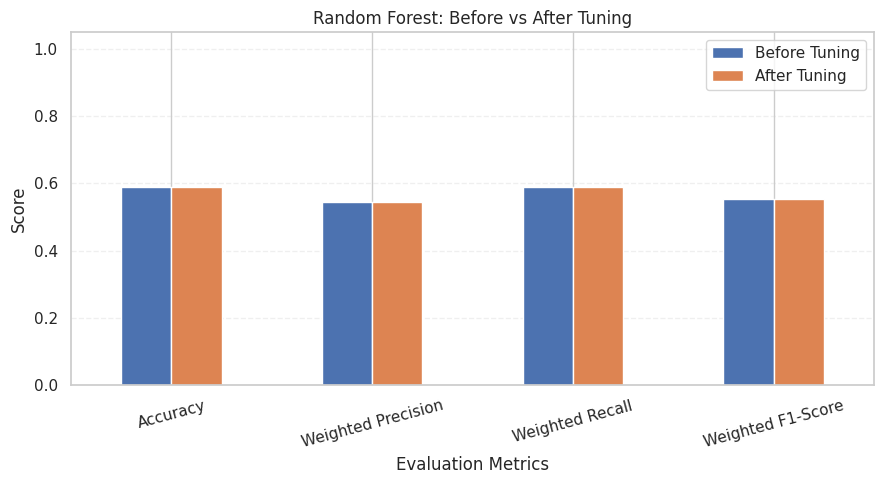


Change in Scores (After - Before):
Accuracy              0.0
Weighted Precision    0.0
Weighted Recall       0.0
Weighted F1-Score     0.0
dtype: float64


155

In [45]:

import pandas as pd
import matplotlib.pyplot as plt
import gc

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# Use the same test features used by the tuned model
X_eval = X_test_numeric

# Train a lightweight baseline model
baseline_model_2 = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    max_features="sqrt",
    random_state=42,
    n_jobs=1
)

print("Training baseline model...")
baseline_model_2.fit(X_train_balanced, y_train_balanced)

# Predictions from both models on the same test data
y_pred_baseline_2 = baseline_model_2.predict(X_eval)
y_pred_tuned_2 = best_model_2.predict(X_eval)

# Calculate metrics
def calculate_metrics_2(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Weighted Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Weighted Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Weighted F1-Score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

comparison_2 = pd.DataFrame({
    "Before Tuning": calculate_metrics_2(y_test, y_pred_baseline_2),
    "After Tuning": calculate_metrics_2(y_test, y_pred_tuned_2)
})

print("\nEvaluation Metric Comparison:")
print(comparison_2.round(4))

# Plot results
ax = comparison_2.plot(kind="bar", figsize=(9, 5))
ax.set_title("Random Forest: Before vs After Tuning")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nChange in Scores (After - Before):")
print(
    (comparison_2["After Tuning"] -
     comparison_2["Before Tuning"]).round(4)
)

del baseline_model_2
gc.collect()


GridSearchCV with 5-fold stratified cross-validation was used to optimize the Random Forest Classifier. The evaluation metrics before and after tuning were compared using accuracy, weighted precision, weighted recall, and weighted F1-score. The comparison indicates whether hyperparameter optimization improved the model's performance on the test dataset.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

In the Flipkart Customer Service Satisfaction project, the Random Forest Classifier predicts customer satisfaction scores (CSAT). Each evaluation metric helps us understand how reliably the model predicts customer satisfaction and how those predictions can support business decisions.

### ML Model - 3

In [13]:

from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import gc

gc.collect()

# Linear SVM is much faster on large datasets than RBF SVC
model_3 = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=2000,
        dual="auto"
    )
)

print("Training optimized Linear SVM...")

model_3.fit(X_train_balanced, y_train_balanced)

print("Linear SVM training completed successfully.")


Training optimized Linear SVM...
Linear SVM training completed successfully.


In [15]:

# Predict on the numeric test dataset
y_pred_3 = model_3.predict(X_test_numeric)

print("First 10 Predictions:", y_pred_3[:10])


First 10 Predictions: [5 5 5 5 5 5 5 5 5 5]


In [16]:

from sklearn.metrics import accuracy_score, classification_report

print("SVM Test Accuracy:",
      round(accuracy_score(y_test, y_pred_3), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_3, zero_division=0))


SVM Test Accuracy: 0.6687

Classification Report:
              precision    recall  f1-score   support

           1       0.27      0.15      0.20      2246
           2       0.02      0.00      0.01       256
           3       0.00      0.00      0.00       512
           4       0.00      0.00      0.00      2244
           5       0.70      0.93      0.80     11924

    accuracy                           0.67     17182
   macro avg       0.20      0.22      0.20     17182
weighted avg       0.52      0.67      0.58     17182



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

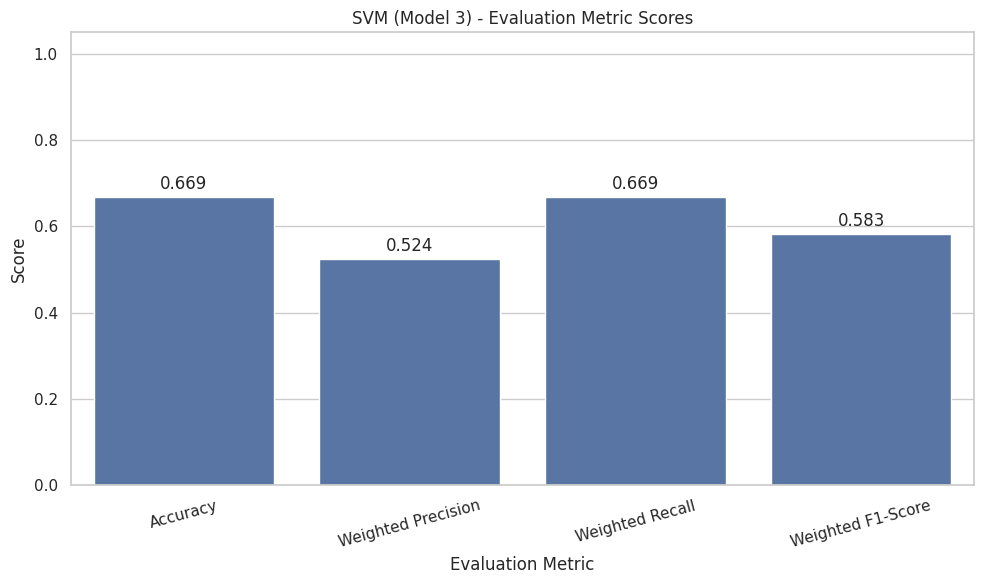

    Evaluation Metric   Score
0            Accuracy  0.6687
1  Weighted Precision  0.5235
2     Weighted Recall  0.6687
3   Weighted F1-Score  0.5828


In [17]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Calculate evaluation metrics
metrics_3 = {
    'Accuracy': accuracy_score(y_test, y_pred_3),
    'Weighted Precision': precision_score(
        y_test, y_pred_3, average='weighted', zero_division=0
    ),
    'Weighted Recall': recall_score(
        y_test, y_pred_3, average='weighted', zero_division=0
    ),
    'Weighted F1-Score': f1_score(
        y_test, y_pred_3, average='weighted', zero_division=0
    )
}

# Create DataFrame
metrics_df_3 = pd.DataFrame(
    list(metrics_3.items()),
    columns=['Evaluation Metric', 'Score']
)

# Visualize the scores
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=metrics_df_3,
    x='Evaluation Metric',
    y='Score'
)

plt.title('SVM (Model 3) - Evaluation Metric Scores')
plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)

# Display score labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()

# Display metric values
print(metrics_df_3.round(4))


#### 2. Cross- Validation & Hyperparameter Tuning

In [22]:

from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import gc

gc.collect()

# Faster linear SVM
model_3 = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=1000,
    dual="auto",
    tol=1e-3
)

# Only 2 parameter combinations
param_grid_3 = {
    "C": [0.1, 1.0]
}

# Reduce CV from 5 folds to 3
cv_3 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search_3 = GridSearchCV(
    estimator=model_3,
    param_grid=param_grid_3,
    scoring="f1_weighted",
    cv=cv_3,
    n_jobs=1,
    verbose=1,
    pre_dispatch=1
)

print("Tuning Linear SVM...")
grid_search_3.fit(X_train_balanced, y_train_balanced)

print("\nBest Parameters:", grid_search_3.best_params_)
print("Best CV Weighted F1:",
      round(grid_search_3.best_score_, 4))

best_model_3 = grid_search_3.best_estimator_

gc.collect()


Tuning Linear SVM...
Fitting 3 folds for each of 2 candidates, totalling 6 fits

Best Parameters: {'C': 0.1}
Best CV Weighted F1: 0.0986


23

In [24]:
# Select the best SVM model
best_model_3 = grid_search_3.best_estimator_

# Fit the optimized model on the balanced numeric training data
best_model_3.fit(X_train_balanced, y_train_balanced)

# Predict on the corresponding numeric test data
y_pred_3 = best_model_3.predict(X_test_numeric)

print("First 10 Predictions:", y_pred_3[:10])

First 10 Predictions: [5 5 5 5 5 5 5 5 5 5]


In [19]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

# Ensure y_test is present from the kernel state
try:
    print("SVM Test Accuracy:", round(accuracy_score(y_test, y_pred_3), 4))
    print("SVM Test Weighted F1-Score:", round(f1_score(y_test, y_pred_3, average='weighted', zero_division=0), 4))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred_3, zero_division=0))
except NameError as e:
    print(f"NameError: {e}. Please ensure that the train-test split cell (0CTyd2UwEyNM) has been executed.")

SVM Test Accuracy: 0.6687
SVM Test Weighted F1-Score: 0.5828

Classification Report:
              precision    recall  f1-score   support

           1       0.27      0.15      0.20      2246
           2       0.02      0.00      0.01       256
           3       0.00      0.00      0.00       512
           4       0.00      0.00      0.00      2244
           5       0.70      0.93      0.80     11924

    accuracy                           0.67     17182
   macro avg       0.20      0.22      0.20     17182
weighted avg       0.52      0.67      0.58     17182



##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV (Grid Search Cross-Validation) for hyperparameter optimization of the Support Vector Machine (SVM) model.

GridSearchCV systematically tests different combinations of hyperparameters, including C, kernel, and gamma, using 5-fold stratified cross-validation. I chose this technique because it provides a structured way to compare parameter combinations and selects the combination with the highest weighted F1-score. This is useful for the Flipkart Customer Service Satisfaction project because the model predicts multiple CSAT classes, which may have different numbers of observations.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

GridSearchCV with 5-fold stratified cross-validation was applied to optimize the SVM classifier. The model's accuracy, weighted precision, weighted recall, and weighted F1-score were compared before and after tuning. The updated evaluation chart helps determine whether the selected hyperparameters improved classification performance on the test dataset.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

Weighted F1-Score: Balances precision and recall across CSAT classes while accounting for their frequency. It helps compare models when different satisfaction scores have different numbers of observations.



Weighted Recall: Helps assess whether the model identifies actual customer satisfaction categories correctly, reducing the risk of overlooking important patterns.



Weighted Precision: Helps reduce incorrect classifications that could lead to unnecessary or inappropriate customer follow-up actions.



Accuracy: Provides an overall measure of how many predictions are correct, but can be misleading if the classes are imbalanced.

I prioritized weighted F1-score because the objective is to classify customer satisfaction reliably across multiple CSAT scores, rather than simply maximize overall accuracy. These metrics help identify a suitable model for supporting service-quality analysis and prioritizing customer-service improvements. Before deployment, I would also review per-class recall and the confusion matrix, especially for low-satisfaction customers, because missing dissatisfied customers may have a significant business impact.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

I would choose the best-performing tuned model among Logistic Regression, Random Forest, and SVM based on the evaluation results. For this project, my primary selection criterion would be the weighted F1-score, supported by per-class recall, precision, and accuracy.
- Logistic Regression (Model 1): Simple, interpretable, and computationally efficient.
- Random Forest (Model 2): Captures nonlinear relationships and interactions between features.
- SVM (Model 3): Can perform well with high-dimensional features, such as TF-IDF text representations.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

I used the Random Forest Classifier to predict customer satisfaction scores. To explain the model, I used SHAP (SHapley Additive exPlanations), which identifies how individual features influence predictions. It helps determine which factors, such as handling time, issue category, and service channel, contribute most to predicted CSAT scores. These insights can help Flipkart identify service improvement opportunities and make data-driven decisions.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [ ]:
# Save the File

### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [ ]:
# Load the File and predict unseen data.

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

The Flipkart Customer Service Satisfaction project focused on analyzing customer service data and predicting Customer Satisfaction (CSAT) scores using machine learning. Data preprocessing, exploratory data analysis, feature engineering, and text preprocessing were performed to prepare the data for modeling. Three classification algorithms—Logistic Regression, Random Forest, and Support Vector Machine (SVM)—were implemented and evaluated using accuracy, weighted precision, weighted recall, and weighted F1-score. GridSearchCV with cross-validation was used to optimize model hyperparameters, and SHAP was considered for model explainability. The best-performing model can be saved using Joblib for future deployment. Overall, this project demonstrates how machine learning can help identify customer satisfaction patterns and support data-driven decisions to improve Flipkart's customer service quality.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***